# ICU Mortality Prediction

**Hands-on Machine Learning: final project**

**Group members:** Fatoumata OULARE, Lydia BENOSMANE, Marina GELLER YAMAGUTI

**Data:** [WiDS Datathon 2020 (Kaggle)](https://www.kaggle.com/competitions/widsdatathon2020/data)

**How to run**

*   Download `training_v2.csv`, `unlabeled.csv` and `WiDS Datathon 2020 Dictionary.csv` into `data/raw/`

*   Python 3.12 with the packages of `requirements.txt`

*   A full run takes about 25 minutes on a laptop

## 1. Introduction

### 1.1 Task

When a patient arrives in an intensive care unit (ICU), the team records vital signs, lab results, the reason for admission and a few chronic conditions. Our task is to estimate the probability that the patient will **die before leaving the hospital**, using **only what is known after the first 24 hours of the ICU stay**.
The target is only known at discharge while the features are routine measurements. That is the setting where a predictive model is useful, for example to flag high-risk patients early. It is a **binary classification** problem. Hospitals already use a severity score, **APACHE IVa**, a fixed formula computed from the same first-day data. A useful model has to be at least as good, and to **work in hospitals it has never seen**.

### 1.2 Metrics

Only about **9%** of the patients die, so the **accuracy** is misleading. Predicting "survives" for everybody already gives about **91%**.

We use instead:

*   **ROC-AUC**: probability that a random death is ranked above a random survivor (0.5 = random, 1 = perfect). It's the official Kaggle metric.

*   **PR-AUC** (average precision): focuses on the rare class, chance level = death rate (~0.09)

*   **Recall** and **precision** at a chosen threshold: the share of deaths that trigger an alert, and the share of alerts that are real deaths

*   **Brier score** and **calibration curve**: are the predicted probabilities numerically correct?

### 1.3 State of the art

The competition (January–February 2020) attracted 951 teams. Scores are ROC-AUC on Kaggle's private test set, whose labels were never released.

| Source | ROC-AUC | Validation | Main methods |
|:--|--:|:--|:--|
| [1st: Women Power](https://www.kaggle.com/competitions/widsdatathon2020/writeups/women-power-1st-place-approach) | 0.91497 | not grouped | Large ensemble (CatBoost, XGBoost, LightGBM, neural nets), 3-level stacking, pseudo-labelling |
| [2nd: nullset](https://www.kaggle.com/competitions/widsdatathon2020/writeups/nullset-2nd-place-solution) | 0.91485 | 8-fold | 26 submissions blended, group statistics by hospital |
| [3rd: Prevision.io](https://www.kaggle.com/competitions/widsdatathon2020/writeups/prevision-io-3rd-place-solution) | 0.91445 | repeated stratified K-fold | 2 LightGBM + 1 neural net, pseudo-labelling |
| [6th: Dihydrogen Oxide](https://www.kaggle.com/competitions/widsdatathon2020/writeups/dihydrogen-oxide-6th-place-solution) | 0.91395 | **grouped by hospital** | Stacking of XGBoost and LightGBM |
| [14th: u++ & mtmt](https://www.kaggle.com/competitions/widsdatathon2020/writeups/u-mtmt-14th-place-approach-summary) | 0.91271 (best single LightGBM: 0.9097 in CV) | not stated | Stacking of 55–73 models |
| [Ren, Zhao & Zhang (2022)](https://doi.org/10.1155/2022/3938492) | 0.879 | not available | Stacked ensemble |
| [Caires Silveira et al. (2022)](https://doi.org/10.5492/wjccm.v11.i5.317) | 0.85 | 80/20 random split, 1,087 patients | Random forest |

We see that:

*   The leaderboard is very tight: the 50th team scored 0.91013, only 0.005 below the winner. The gains at the top come from large ensembles and test-set tricks

*   Most top teams dropped the APACHE predictions and the hospital identifiers

*   None of them reports calibration or a decision threshold, and only the 6th place validates on new hospitals

*   Our scores are not directly comparable with the leaderboard: the Kaggle test labels are not public, so we evaluate on our own held-out hospitals

### 1.4 Our approach

We do not try to win the leaderboard. We answer three questions:

1.  **Does the model overfit the training hospitals?** We evaluate on **entire unseen hospitals** and compare with the performance on the training patients

2.  **What other sources of overfitting are there?** Model complexity, hospital "fingerprints" in the features, and preprocessing fitted on all the data

3.  **How close to the state of the art can simple models get with a careful preprocessing?**

APACHE IVa is kept as a **clinical benchmark**, not as a feature.

## 2. Preprocessing

In [1]:
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn import (
    base,
    calibration,
    compose,
    dummy,
    ensemble,
    feature_selection,
    impute,
    linear_model,
    metrics,
    model_selection,
    pipeline,
    preprocessing,
)

In [2]:
%config InlineBackend.figure_format="retina"  # For high DPI display

sns.set_style("darkgrid")
sns.set_context("notebook")
warnings.filterwarnings("ignore")  # Hide library warnings

RANDOM_STATE = 42

print(sklearn.__version__)  # Version tested on sklearn.__version__ == 1.9.x
print(lgb.__version__)

1.9.1
4.7.0


### Utility Functions

In [3]:
# Print each named variable as "name = value" with 4 significant digits
def pprint_var(**kwargs):
    for k, v in kwargs.items():
        print(f"{k} = {v:.4g}")

### 2.1 Data loading

One row per ICU stay. The data dictionary describes every column and assigns it to a category.

In [4]:
DATA = Path("data/raw")

raw_df = pd.read_csv(DATA / "training_v2.csv")
dict_df = pd.read_csv(DATA / "WiDS Datathon 2020 Dictionary.csv")

print(raw_df.shape)
raw_df.head()

(91713, 186)


,encounter_id,patient_id,hospital_id,hospital_death,age,bmi,elective_surgery,ethnicity,gender,height,...,aids,cirrhosis,diabetes_mellitus,hepatic_failure,immunosuppression,leukemia,lymphoma,solid_tumor_with_metastasis,apache_3j_bodysystem,apache_2_bodysystem
0,66154,25312,118,0,68.0,22.73,0,Caucasian,M,180.3,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Sepsis,Cardiovascular
1,114252,59342,81,0,77.0,27.42,0,Caucasian,F,160.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,Respiratory,Respiratory
2,119783,50777,118,0,25.0,31.95,0,Caucasian,F,172.7,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Metabolic,Metabolic
3,79267,46918,118,0,81.0,22.64,1,Caucasian,F,165.1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Cardiovascular,Cardiovascular
4,92056,34377,33,0,19.0,NaN,0,Caucasian,M,188.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,Trauma,Trauma


In [5]:
display(raw_df.dtypes.value_counts())
display(dict_df.query("`Variable Name` == 'd1_lactate_max'"))

float64    170
int64        8
str          8
Name: count, dtype: int64

,Category,Variable Name,Unit of Measure,Data Type,Description,Example
119,labs,d1_lactate_max,mmol/L,numeric,The highest lactate concentration for the pati...,1


In [6]:
category_of = dict_df.set_index("Variable Name")["Category"]
feature_groups = category_of.reindex(raw_df.columns).fillna(
    "not in dictionary"
)
feature_groups.value_counts()

Category
labs                  60
vitals                52
APACHE covariate      28
labs blood gas        16
demographic           15
APACHE comorbidity     8
identifier             3
APACHE prediction      2
APACHE grouping        2
Name: count, dtype: int64

*   `h1_*` = min/max during the **first hour**, `d1_*` = min/max during the **first day**, `*_apache` = the value used by the APACHE score (worst value of the first day)

*   Most features are numeric, 8 are text categories (sex, ethnicity, ...)

### 2.2 Target balance

In [7]:
TARGET = "hospital_death"

death_rate = raw_df[TARGET].mean()
pprint_var(deaths=raw_df[TARGET].sum(), death_rate=death_rate)
pprint_var(accuracy_always_survives=1 - death_rate)

deaths = 7915
death_rate = 0.0863
accuracy_always_survives = 0.9137


**Observations**

8.63% of the stays end in death (7,915 / 91,713). A model always answering "survives" reaches 91.37% accuracy while detecting no death at all, which is why the accuracy is not one of our metrics.

### 2.3 Missing values

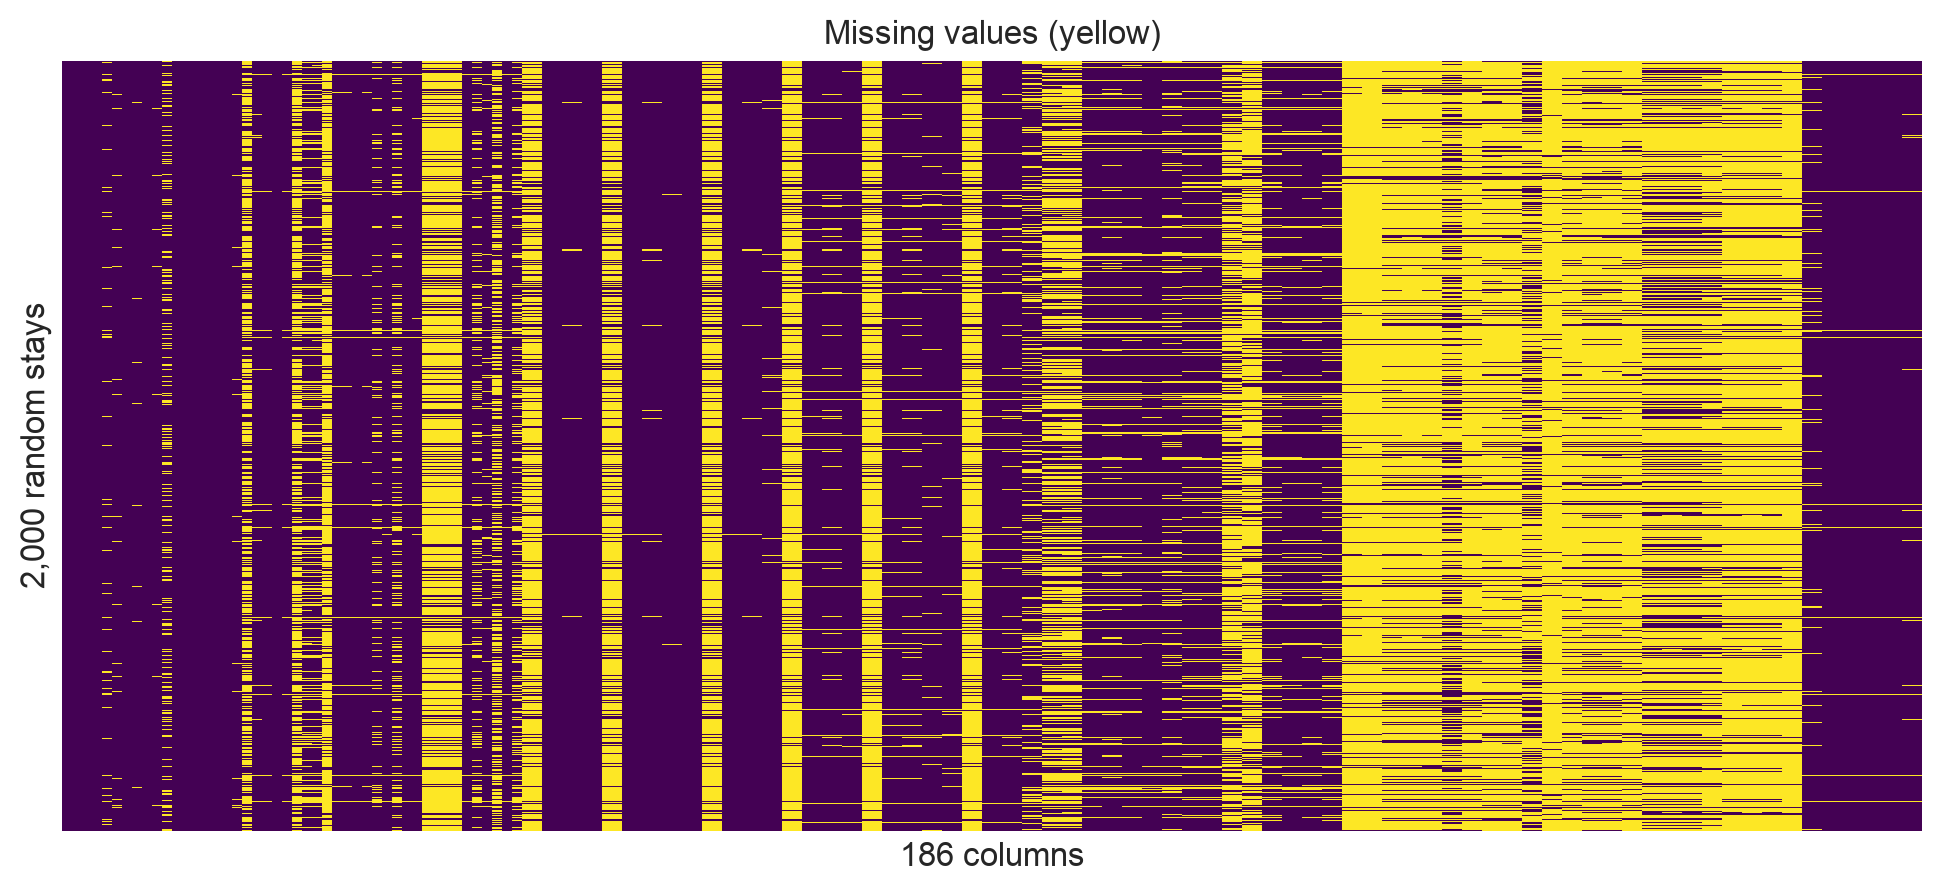

In [8]:
plt.figure(figsize=(12, 5))
ax = sns.heatmap(
    raw_df.sample(2000, random_state=RANDOM_STATE).isna(),
    cbar=False,
    cmap="viridis",
    xticklabels=False,
    yticklabels=False,
)
ax.set(
    xlabel="186 columns",
    ylabel="2,000 random stays",
    title="Missing values (yellow)",
)
plt.show()

In [9]:
missing_share = raw_df.isna().mean().sort_values(ascending=False)

print(
    f"Columns with missing values: {(missing_share > 0).sum()} / {raw_df.shape[1]}"
)
for limit in (0.5, 0.8, 0.9):
    print(
        f"  more than {limit:.0%} missing: {(missing_share > limit).sum()} columns"
    )
print(
    f"Rows with at least one missing value: {raw_df.isna().any(axis=1).mean():.2%}"
)

missing_share.head(8)

Columns with missing values: 175 / 186
  more than 50% missing: 74 columns
  more than 80% missing: 34 columns
  more than 90% missing: 6 columns
Rows with at least one missing value: 99.97%


h1_bilirubin_min        0.922650
h1_bilirubin_max        0.922650
h1_lactate_max          0.919924
h1_lactate_min          0.919924
h1_albumin_max          0.913982
h1_albumin_min          0.913982
h1_pao2fio2ratio_min    0.874413
h1_pao2fio2ratio_max    0.874413
dtype: float64

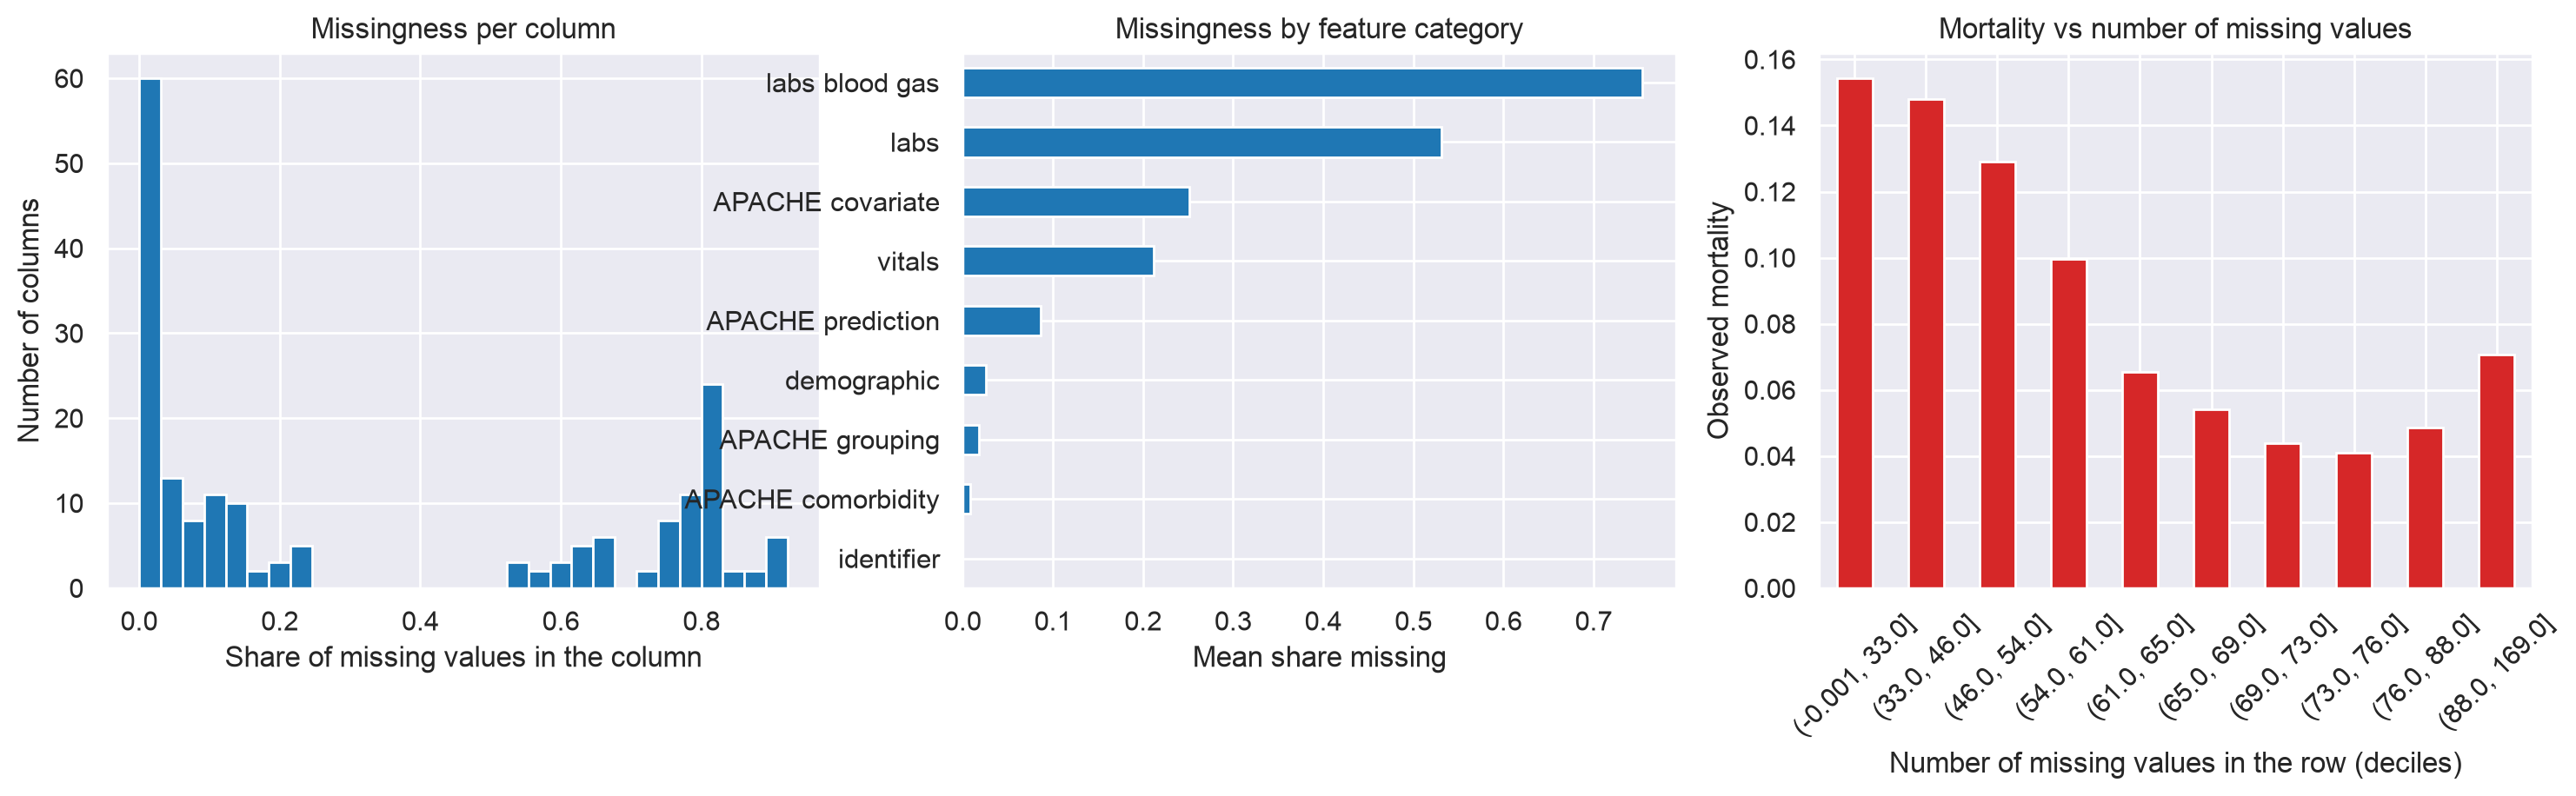

In [10]:
n_missing_per_row = raw_df.isna().sum(axis=1)
missing_decile = pd.qcut(n_missing_per_row, 10, duplicates="drop")

fig, ax = plt.subplots(1, 3, figsize=(18, 4))
missing_share.plot.hist(bins=30, ax=ax[0])
ax[0].set(
    xlabel="Share of missing values in the column",
    ylabel="Number of columns",
    title="Missingness per column",
)

missing_share.groupby(feature_groups).mean().sort_values().plot.barh(ax=ax[1])
ax[1].set(
    xlabel="Mean share missing",
    ylabel="",
    title="Missingness by feature category",
)

raw_df.groupby(missing_decile, observed=True)[TARGET].mean().plot.bar(
    ax=ax[2], color="tab:red"
)
ax[2].set(
    xlabel="Number of missing values in the row (deciles)",
    ylabel="Observed mortality",
    title="Mortality vs number of missing values",
)
ax[2].tick_params(axis="x", rotation=45)
plt.show()

**Observations**

We see that:

*   175 of the 186 columns have missing values, 74 are more than 50% missing. **99.97% of the rows** have at least one missing value, so dropping incomplete rows is impossible

*   **Missingness is informative** (right plot): patients with the *fewest* missing values have the *highest* mortality. Clinicians order more tests when they are worried, so the values are not missing at random

**Consequence:** we never use an imputation that hides that a value was missing. LightGBM and the random forest handle missing values natively, and the logistic regression gets a 0/1 "was missing" indicator.

### 2.4 Distributions and outliers

We compare a few clinically important variables between survivors and non-survivors.

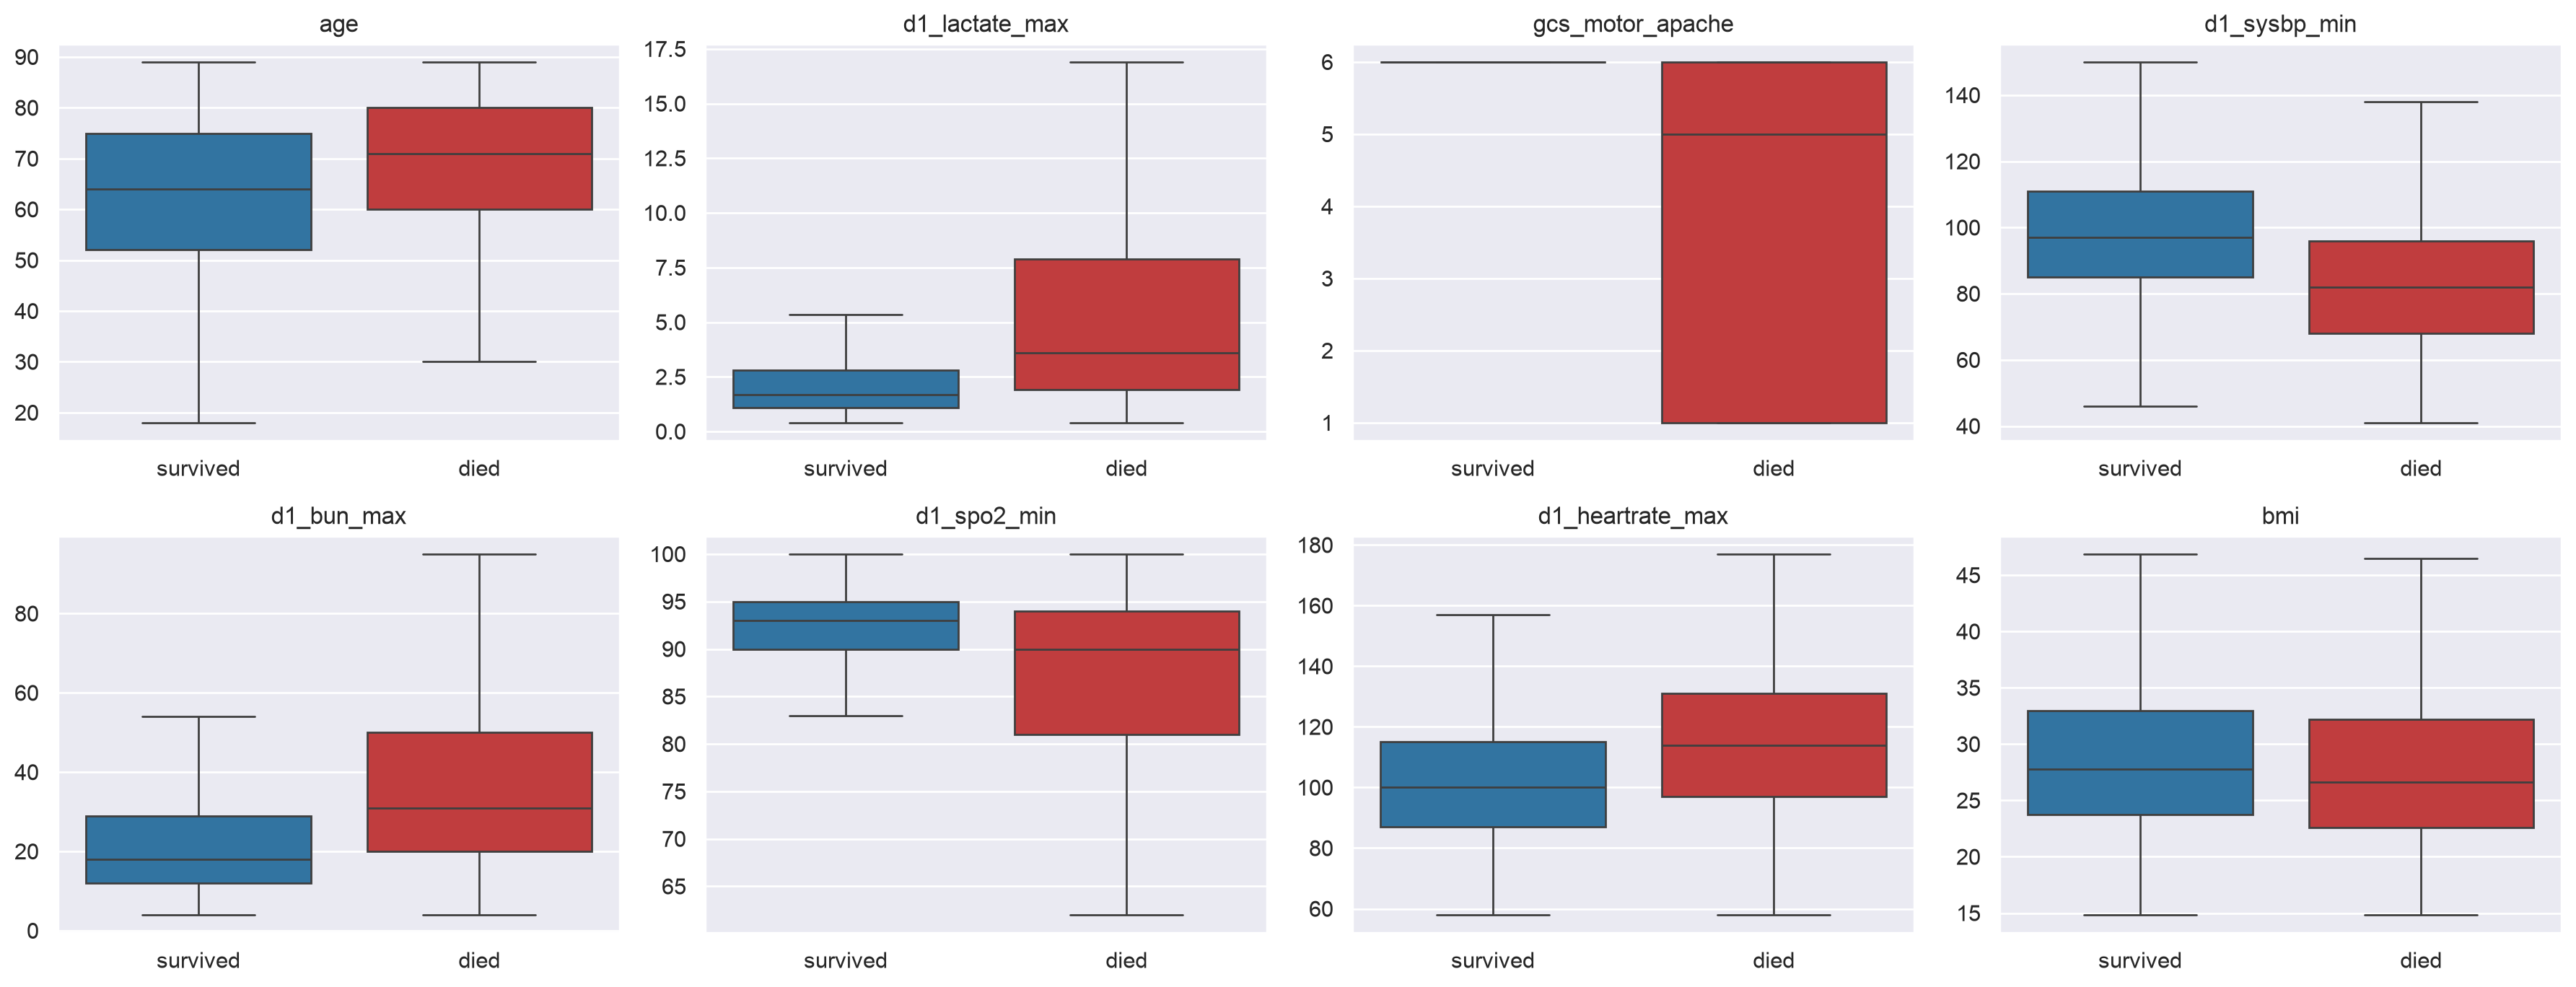

In [11]:
KEY_FEATURES = [
    "age",
    "d1_lactate_max",
    "gcs_motor_apache",
    "d1_sysbp_min",
    "d1_bun_max",
    "d1_spo2_min",
    "d1_heartrate_max",
    "bmi",
]

outcome_df = raw_df[KEY_FEATURES].assign(
    outcome=raw_df[TARGET].map({0: "survived", 1: "died"})
)

fig, ax = plt.subplots(2, 4, figsize=(18, 7))
for axis, feature in zip(ax.ravel(), KEY_FEATURES):
    sns.boxplot(
        data=outcome_df,
        x="outcome",
        y=feature,
        hue="outcome",
        showfliers=False,
        palette={"survived": "tab:blue", "died": "tab:red"},
        ax=axis,
    )
    axis.set(xlabel="", ylabel="", title=feature)
plt.tight_layout()
plt.show()

Are the extreme values errors? We look at the range of a few vital signs, and count a few impossible values.

In [12]:
APACHE_PREDICTIONS = [
    "apache_4a_hospital_death_prob",
    "apache_4a_icu_death_prob",
]
VITALS = [
    "d1_heartrate_max",
    "d1_heartrate_min",
    "d1_temp_min",
    "d1_sysbp_min",
    "d1_resprate_max",
    "bmi",
]

display(raw_df[VITALS].describe().T)

# Pairs of columns (minimum, maximum) of the same measurement
MIN_MAX = [
    (col, col.replace("_min", "_max"))
    for col in raw_df.columns
    if col.endswith("_min")
]
n_inverted = sum(
    (raw_df[col_min] > raw_df[col_max]).sum() for col_min, col_max in MIN_MAX
)

pprint_var(
    share_aged_89=(raw_df.age == 89).mean(),
    negative_pre_icu_stays=(raw_df.pre_icu_los_days < 0).sum(),
    inverted_min_max=n_inverted,
    apache_equal_minus_1=(raw_df[APACHE_PREDICTIONS[0]] == -1).sum(),
)

,count,mean,std,min,25%,50%,75%,max
d1_heartrate_max,91568.0,103.000568,22.017346,58.000000,87.000000,101.000000,116.000000,177.00000
d1_heartrate_min,91568.0,70.321848,17.115903,0.000000,60.000000,69.000000,81.000000,175.00000
d1_temp_min,89389.0,36.268391,0.745147,31.889000,36.100000,36.400000,36.660000,37.80000
d1_sysbp_min,91554.0,96.923870,20.677930,41.000000,83.000000,96.000000,110.000000,160.00000
d1_resprate_max,91328.0,28.882774,10.701973,14.000000,22.000000,26.000000,32.000000,92.00000
bmi,88284.0,29.185818,8.275142,14.844926,23.641975,27.654655,32.930206,67.81499


share_aged_89 = 0.01038
negative_pre_icu_stays = 778
inverted_min_max = 1126
apache_equal_minus_1 = 2371


**Observations**

*   As expected, the patients who died are older, have a higher lactate (poor tissue perfusion), a lower motor GCS (reduced consciousness), a lower minimum blood pressure and oxygen saturation, a higher urea (BUN, kidney function) and a higher heart rate. The BMI barely differs

*   The ranges of the vital signs are physiologically plausible for ICU patients (e.g. a minimum heart rate of 0 can be a cardiac arrest). Age is capped at 89, a usual de-identification rule

*   A few values are impossible and are fixed in Section 2.7: negative pre-ICU stays, minimum larger than maximum, and APACHE predictions equal to `-1`

### 2.5 Categorical variables and correlations

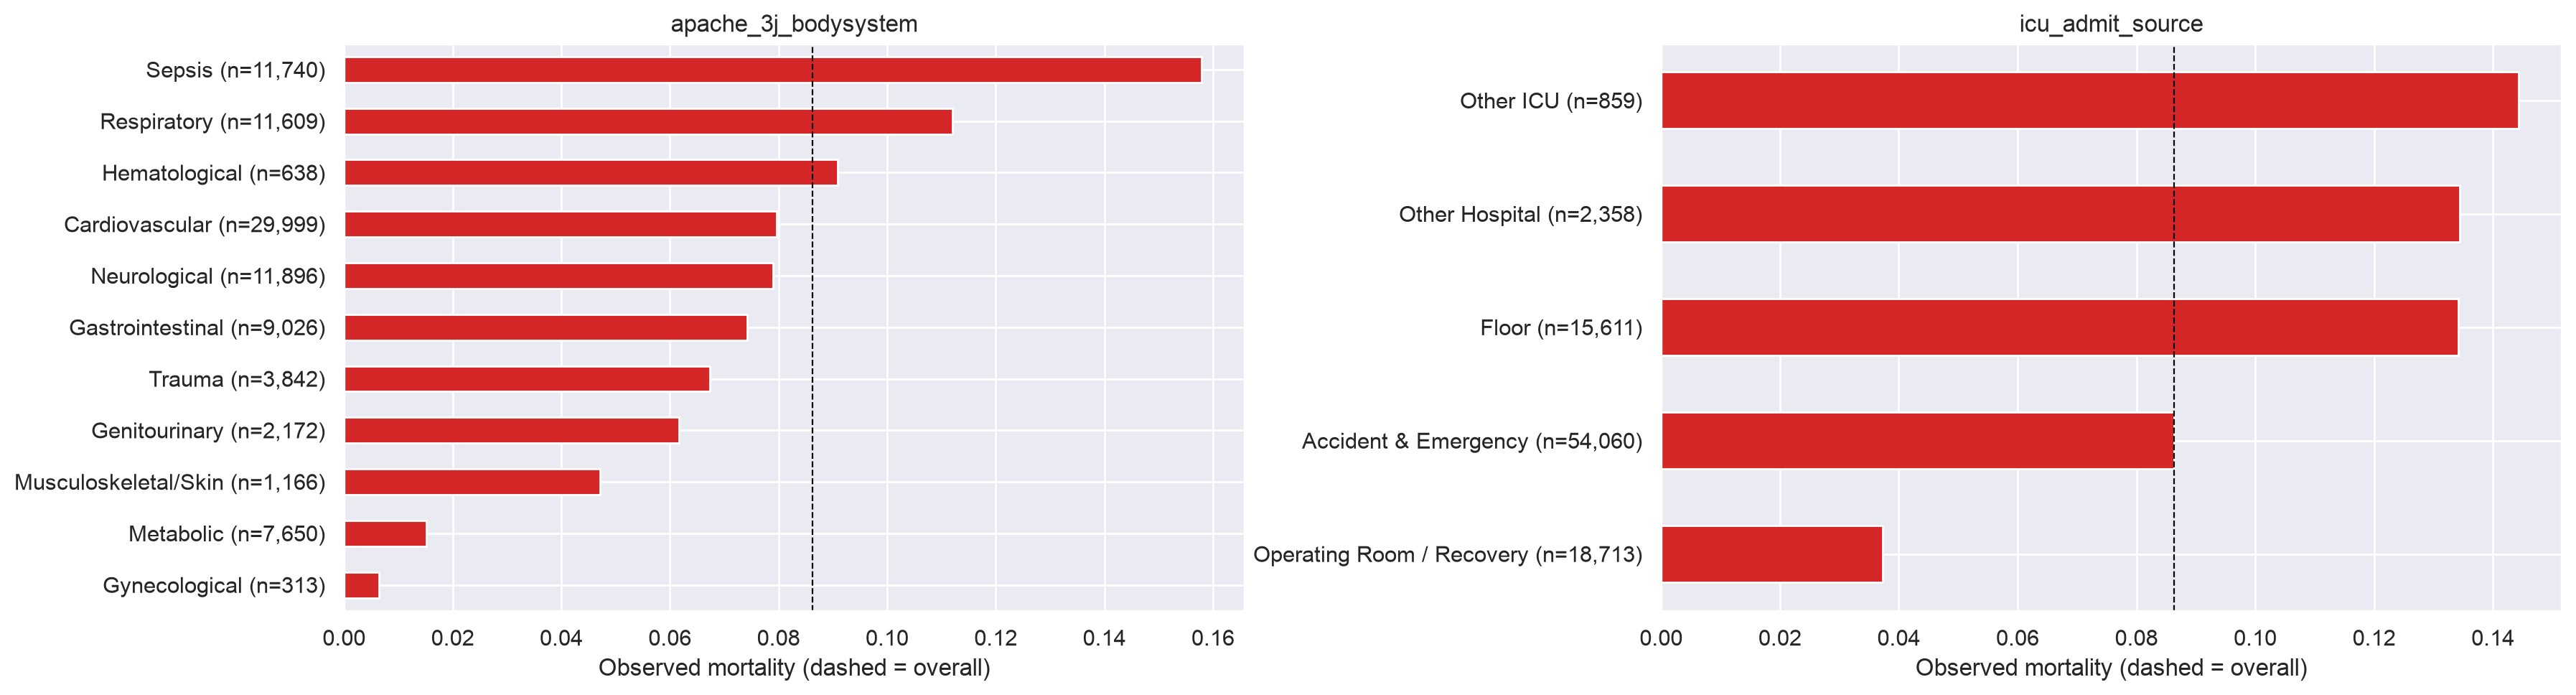

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5))
for axis, column in zip(ax, ["apache_3j_bodysystem", "icu_admit_source"]):
    summary_df = (
        raw_df.groupby(column)[TARGET]
        .agg(["mean", "size"])
        .sort_values("mean")
    )
    summary_df.index = [
        f"{name} (n={size:,})" for name, size in summary_df["size"].items()
    ]
    summary_df["mean"].plot.barh(ax=axis, color="tab:red")
    axis.axvline(death_rate, color="k", ls="--", lw=0.8)
    axis.set(
        xlabel="Observed mortality (dashed = overall)", ylabel="", title=column
    )
plt.tight_layout()
plt.show()

**Is the task too easy?** For each numeric feature, we use its raw value directly as a score and compute the ROC-AUC (oriented to be ≥ 0.5). If one feature had an AUC close to 1, the task would be trivial.

In [14]:
ID_COLUMNS = ["encounter_id", "patient_id", "hospital_id", "icu_id"]
numeric_columns = raw_df.select_dtypes("number").columns.drop(
    [TARGET] + ID_COLUMNS + APACHE_PREDICTIONS
)

univariate_auc = {}
for column in numeric_columns:
    known = raw_df[column].notna()
    auc = metrics.roc_auc_score(
        raw_df.loc[known, TARGET], raw_df.loc[known, column]
    )
    univariate_auc[column] = max(
        auc, 1 - auc
    )  # A low value can be as informative as a high one

univariate_auc = pd.Series(univariate_auc, name="ROC-AUC").sort_values(
    ascending=False
)
univariate_auc.head(10)

d1_lactate_max              0.736077
d1_lactate_min              0.731183
h1_lactate_min              0.712233
h1_lactate_max              0.709542
d1_sysbp_min                0.705070
d1_sysbp_noninvasive_min    0.704984
gcs_verbal_apache           0.704678
d1_bun_max                  0.703094
bun_apache                  0.698519
ventilated_apache           0.691064
Name: ROC-AUC, dtype: float64

In [15]:
corr_df = raw_df[numeric_columns].corr().abs()
n_pairs = (
    (corr_df > 0.95).sum().sum() - len(corr_df)
) // 2  # Remove the diagonal, count each pair once
pprint_var(pairs_with_corr_above_095=n_pairs)

pairs_with_corr_above_095 = 63


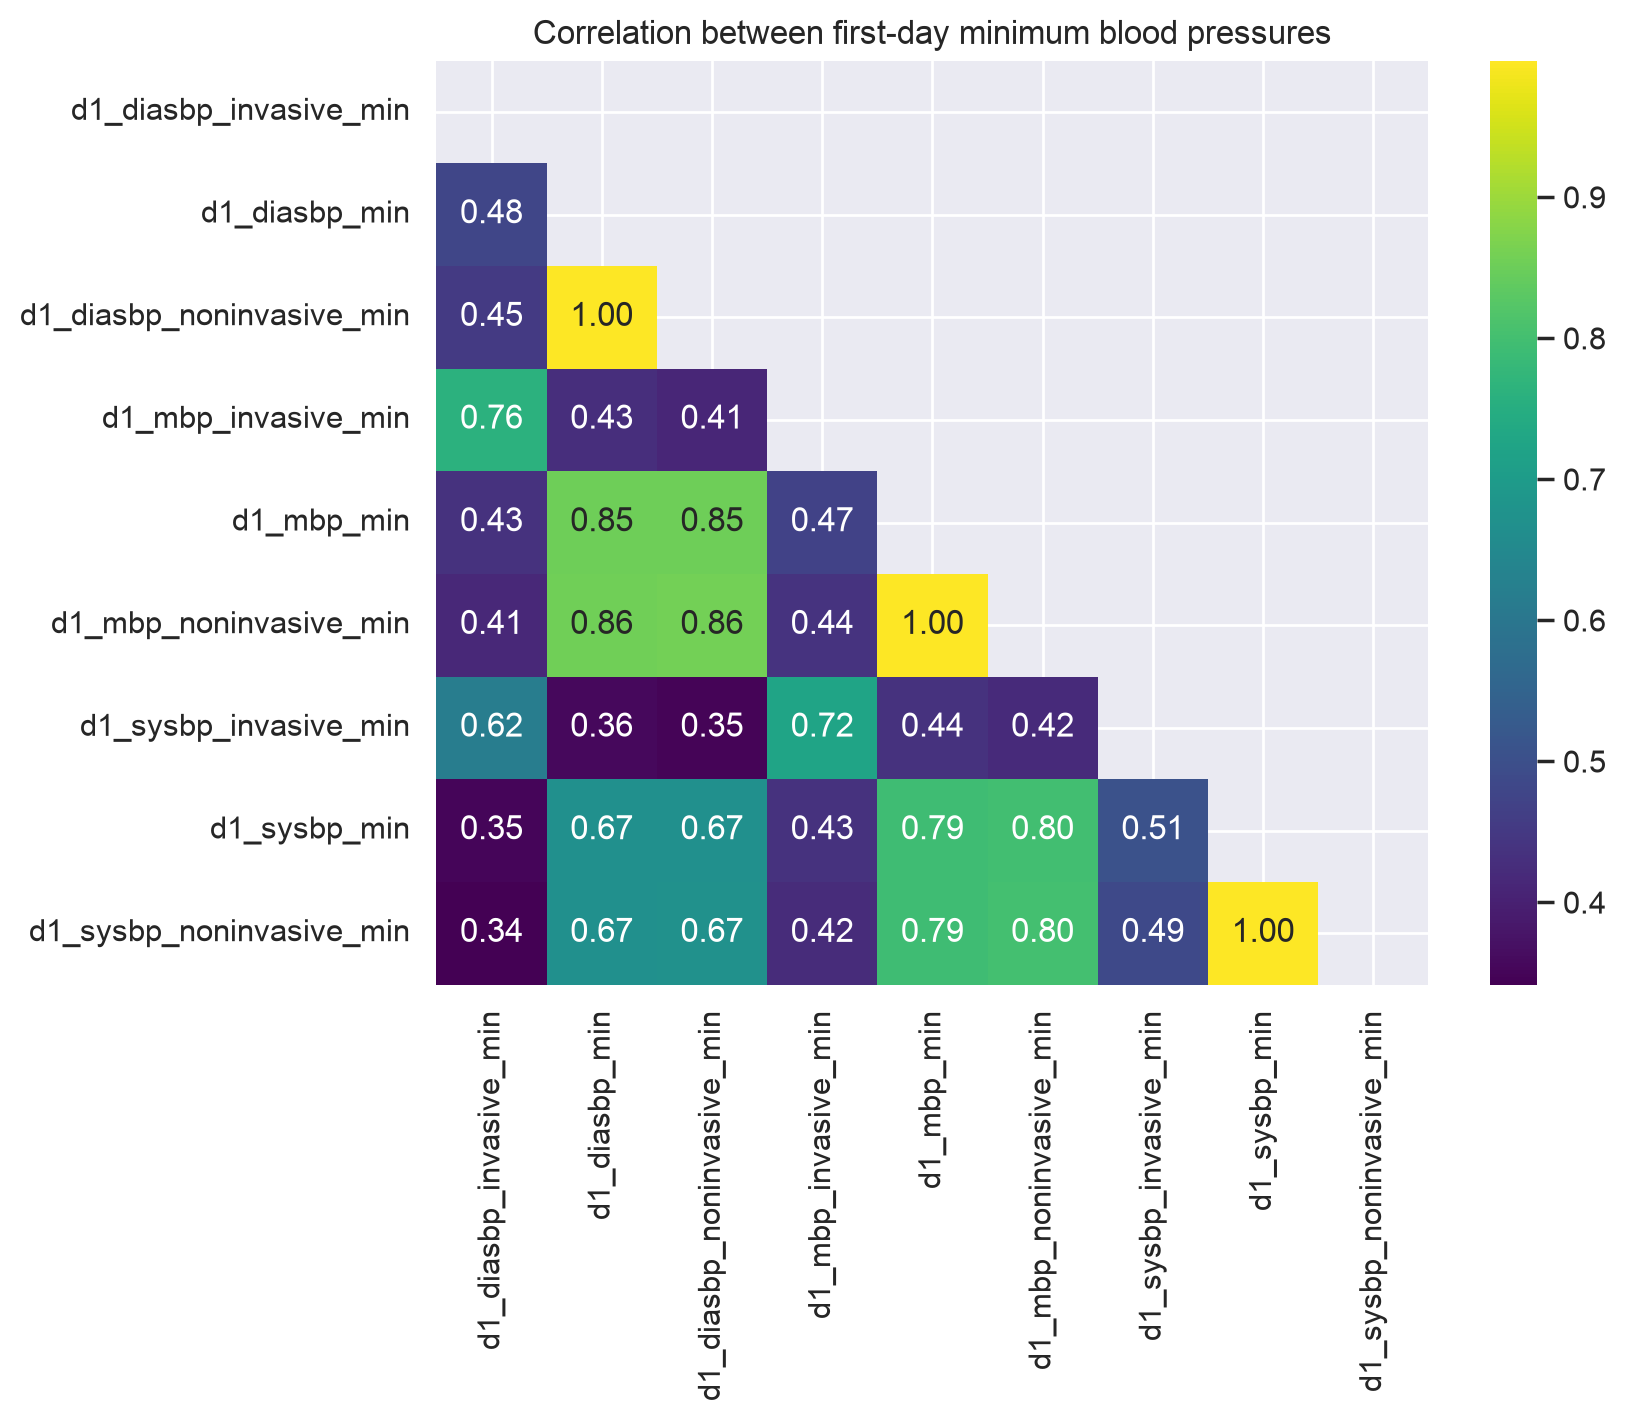

In [16]:
blood_pressure = [
    c
    for c in numeric_columns
    if c.startswith("d1_") and "bp" in c and "min" in c
]

plt.figure(figsize=(8, 6))
mask = np.triu(np.ones_like(raw_df[blood_pressure].corr(), dtype=bool))
ax = sns.heatmap(
    raw_df[blood_pressure].corr(),
    cbar=True,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    mask=mask,
)
ax.set(title="Correlation between first-day minimum blood pressures")
plt.show()

**Observations**

*   The best measured feature (`d1_lactate_max`) reaches a ROC-AUC of only 0.736 on its own. **No single feature gives the answer**, the task is not trivial

*   63 pairs of features have $|r| > 0.95$ (e.g. `h1_*_min` and `h1_*_max` when a lab was measured only once, or invasive and non-invasive blood pressure). We keep them since trees are not harmed by redundancy and the logistic regression is regularized

### 2.6 Identifiers and leakage checks

Leakage = information that would not be available at prediction time or that makes the validation unrealistically easy.

In [17]:
display(raw_df[ID_COLUMNS].nunique())

stays_per_hospital = raw_df.groupby("hospital_id").size()
mortality_per_hospital = raw_df.groupby("hospital_id")[TARGET].mean()
large = stays_per_hospital >= 100
pprint_var(
    median_stays_per_hospital=stays_per_hospital.median(),
    min_mortality_large_hospitals=mortality_per_hospital[large].min(),
    max_mortality_large_hospitals=mortality_per_hospital[large].max(),
)

# Only the hospital column of the unlabeled (Kaggle test) file is read
kaggle_test_hospitals = set(
    pd.read_csv(DATA / "unlabeled.csv", usecols=["hospital_id"]).hospital_id
)
shared = kaggle_test_hospitals & set(raw_df.hospital_id)
print(
    f"Kaggle test file: {len(kaggle_test_hospitals)} hospitals, only {len(shared)} also in training"
)

encounter_id    91713
patient_id      91713
hospital_id       147
icu_id            241
dtype: int64

median_stays_per_hospital = 323
min_mortality_large_hospitals = 0
max_mortality_large_hospitals = 0.2909


Kaggle test file: 66 hospitals, only 9 also in training


In [18]:
apache_df = raw_df[APACHE_PREDICTIONS].where(raw_df[APACHE_PREDICTIONS] >= 0)
has_apache = apache_df.notna().all(axis=1)
pprint_var(share_with_apache=has_apache.mean())

for column in APACHE_PREDICTIONS:
    auc = metrics.roc_auc_score(
        raw_df.loc[has_apache, TARGET], apache_df.loc[has_apache, column]
    )
    pprint_var(**{f"auc_{column}": auc})

share_with_apache = 0.884
auc_apache_4a_hospital_death_prob = 0.8633
auc_apache_4a_icu_death_prob = 0.8585


**Leakage decisions**

| Source | Finding | Decision |
|:--|:--|:--|
| `encounter_id`, `patient_id` | Unique per row (no patient appears twice) | Dropped |
| `hospital_id`, `icu_id` | 147 hospitals with very different mortality; the Kaggle test file contains mostly **other** hospitals | Not used as features, used as **groups** for splitting |
| `apache_4a_*_death_prob` | Output of an existing clinical model computed from the same data | Excluded from the features, kept as a **benchmark** |
| Timing | All features are collected during the first 24 h | Kept |

`readmission_status` is 0 for everybody, so it carries no information and is dropped.

### 2.7 Cleaning

*   Drop the constant column `readmission_status`

*   Merge "Undefined Diagnoses" and "Undefined diagnoses" (same category spelled twice)

*   APACHE predictions equal to `-1` → missing 

*   Negative `pre_icu_los_days` → missing (a negative duration is impossible)

*   Swap inverted min/max values (recording error)

*   Diagnosis codes → categories: 502.01 is a code, not a quantity. We keep the integer part (diagnosis group)

We don't remove more outliers. The provider already clipped extreme values and removing them would delete the sickest patients.

In [19]:
icu_df = raw_df.drop(columns=["readmission_status"])
icu_df["apache_2_bodysystem"] = icu_df["apache_2_bodysystem"].replace(
    "Undefined Diagnoses", "Undefined diagnoses"
)

# -1 is a code for "APACHE could not be computed", not a probability
for col in APACHE_PREDICTIONS:
    icu_df.loc[icu_df[col] < 0, col] = np.nan

# A negative stay before ICU admission is impossible
icu_df.loc[icu_df["pre_icu_los_days"] < 0, "pre_icu_los_days"] = np.nan

# Swap the min and max values recorded in the wrong order
for col_min, col_max in MIN_MAX:
    inverted = icu_df[col_min] > icu_df[col_max]
    icu_df.loc[inverted, [col_min, col_max]] = icu_df.loc[
        inverted, [col_max, col_min]
    ].values

# Diagnosis codes are labels, not quantities: keep the diagnosis group as a text category
for col in ["apache_2_diagnosis", "apache_3j_diagnosis"]:
    icu_df[col] = (
        icu_df[col]
        .floordiv(1)
        .astype("Int64")
        .astype(str)
        .replace("<NA>", np.nan)
    )

print(icu_df.shape)

(91713, 185)


### 2.8 Features

*   Identifiers, target and APACHE predictions are removed

*   `n_missing_values` = number of missing measurements of the patient: a summary of *how intensively the patient was monitored* (Section 2.3)

*   The text categories are **one-hot encoded** with [`pd.get_dummies`](https://pandas.pydata.org/docs/reference/api/pandas.get_dummies.html) (one 0/1 column per category). It does not use the target, so it can be done once, before the split

**Note:** missing values are kept as `NaN`. The random forest and LightGBM handle them natively; for the logistic regression they are imputed inside a pipeline (Section 3.3).

In [20]:
features_df = icu_df.drop(columns=ID_COLUMNS + [TARGET] + APACHE_PREDICTIONS)
features_df["n_missing_values"] = features_df.isna().sum(axis=1)

CATEGORICAL = features_df.select_dtypes(exclude="number").columns.tolist()
xs_df = pd.get_dummies(features_df, columns=CATEGORICAL, dtype=float)
# LightGBM renames columns with spaces or symbols ("Operating Room / Recovery"), so we do it once here
xs_df.columns = xs_df.columns.str.replace(r"[^0-9a-zA-Z_]+", "_", regex=True)

ys = icu_df[TARGET].values
groups = icu_df["hospital_id"].values  # Hospital of each stay

print(CATEGORICAL)
print(xs_df.shape, ys.shape, groups.shape)

['ethnicity', 'gender', 'hospital_admit_source', 'icu_admit_source', 'icu_stay_type', 'icu_type', 'apache_2_diagnosis', 'apache_3j_diagnosis', 'apache_3j_bodysystem', 'apache_2_bodysystem']
(91713, 384) (91713,) (91713,)


### 2.9 Train / test split by hospital

We hold out 20% of the **hospitals** as a test set, never used for training or for choosing the models.

[`GroupShuffleSplit`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) works like `train_test_split`, but keeps all the stays of a hospital on the same side.

**Note:** `test_size=0.2` means 20% of the *hospitals*, not of the stays. Hospitals differ in size and in mortality, so the test set does not have exactly 20% of the stays nor exactly the training death rate. We keep it this way on purpose: a new hospital will never look exactly like the training hospitals, and this lets us see how the model reacts to that difference (Section 4.3).

In [21]:
splitter = model_selection.GroupShuffleSplit(
    n_splits=1, test_size=0.2, random_state=RANDOM_STATE
)
train_idx, test_idx = next(splitter.split(xs_df, ys, groups))

train_xs, test_xs = xs_df.iloc[train_idx], xs_df.iloc[test_idx]
train_ys, test_ys = ys[train_idx], ys[test_idx]
train_groups, test_groups = groups[train_idx], groups[test_idx]

print(
    "train:",
    train_xs.shape,
    "-",
    len(set(train_groups)),
    "hospitals, mortality",
    f"{train_ys.mean():.4f}",
)
print(
    "test: ",
    test_xs.shape,
    "-",
    len(set(test_groups)),
    "hospitals, mortality",
    f"{test_ys.mean():.4f}",
)

train: (70261, 384) - 117 hospitals, mortality 0.0813
test:  (21452, 384) - 30 hospitals, mortality 0.1026


**Observations**

* Comparing our test and training hospitals, we notice that the test hospitals have a higher death rate: 8.13% in the 117 training hospitals (70,261 stays), against 10.26% in the 30 test hospitals (21,452 stays). This is not necessarily a problem, we think it’s actually realistic, since the mortality varies a lot between hospitals: from 0% to 29% among hospitals with at least 100 stays (Section 2.6). So a new hospital will never have exactly the training death rate. Kaggle’s own test set was also mostly made of other hospitals (only 9 of its 66 hospitals are in the training data), so it’s a situation the model would actually face.

* The key point is why the test hospitals have more deaths. We had two theories: the patients are sicker (the features like lactate or ventilation show it, so the model can see it), or the hospitals themselves are different (quality of care, practices, which are not in the features, so the model can’t see it). We check which one in Section 4.3.

## 3. Training

### 3.1 Validation strategy

All the model choices are made with a **5-fold cross-validation grouped by hospital** ([`GroupKFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupKFold.html)) on the training set: the validation hospitals are never in the training folds, as for a new hospital.

We use [`cross_validate`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) with `return_train_score=True`, so that we get for each fold:

*   The ROC-AUC on the **training folds** (patients the model has seen)

*   The ROC-AUC on the **validation fold** (new hospitals)

The difference between the two measures the **overfitting**.

In [22]:
cv = model_selection.GroupKFold(n_splits=5)
SCORING = "roc_auc"

cv_results = {}  # Model name -> scores of each fold


def evaluate(name, model, xs=train_xs):
    scores = model_selection.cross_validate(
        model,
        xs,
        train_ys,
        groups=train_groups,
        cv=cv,
        scoring=SCORING,
        return_train_score=True,
    )
    cv_results[name] = scores
    print(
        f"{name}: train {scores['train_score'].mean():.4f} | validation {scores['test_score'].mean():.4f} ± {scores['test_score'].std():.4f}"
    )

### 3.2 Baseline

A [`DummyClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html) predicts the training death rate for everybody: ROC-AUC = 0.5 by construction. Any useful model must beat it.

In [23]:
# 2. Instantiation
model = dummy.DummyClassifier(strategy="prior")

# 3. Learn (fit) the model and 4. predict, on each fold
evaluate("Dummy", model)

Dummy: train 0.5000 | validation 0.5000 ± 0.0000


### 3.3 Logistic Regression

[`LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) is linear, fast and interpretable. It needs a [`pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html):

*   `imputer`: missing values replaced by the median, **plus a 0/1 "was missing" column** for each feature (`add_indicator=True`), so that the model can still use the missingness

*   `scaler`: standardization, so that the regularization treats all the features equally

We choose the regularization strength `C` (from 0.0001 = very strong to 1 = weak) with a [`GridSearchCV`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

Fitting 5 folds for each of 5 candidates, totalling 25 fits


Best parameter (CV score: 0.8911)
{'model__C': 0.001}


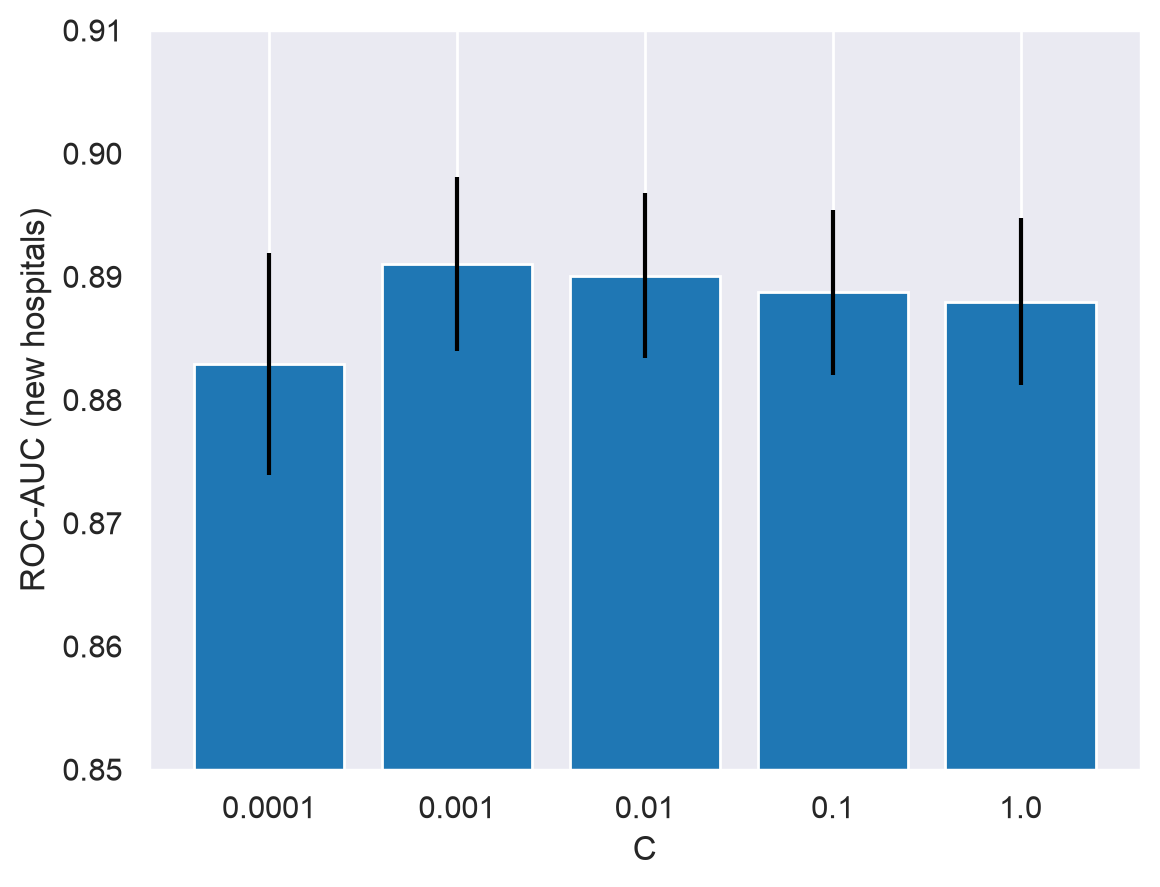

Logistic regression: train 0.8993 | validation 0.8911 ± 0.0071


In [24]:
lr_pipe = pipeline.Pipeline(
    steps=[
        (
            "imputer",
            impute.SimpleImputer(strategy="median", add_indicator=True),
        ),
        ("scaler", preprocessing.StandardScaler()),
        ("model", linear_model.LogisticRegression(max_iter=2000)),
    ]
)

param_grid = {"model__C": [0.0001, 0.001, 0.01, 0.1, 1.0]}

search = model_selection.GridSearchCV(
    lr_pipe, param_grid, scoring=SCORING, cv=cv, n_jobs=-1, verbose=1
)
search.fit(train_xs, train_ys, groups=train_groups)

print(f"Best parameter (CV score: {search.best_score_:.4f})")
print(search.best_params_)

plt.bar(
    [str(c) for c in param_grid["model__C"]],
    search.cv_results_["mean_test_score"],
    yerr=search.cv_results_["std_test_score"],
)
plt.ylim(0.85, 0.91)
plt.xlabel("C")
plt.ylabel("ROC-AUC (new hospitals)")
plt.grid(axis="y")
plt.show()

lr_model = search.best_estimator_
evaluate("Logistic regression", lr_model)

**Observations**

*  We notice that the values of `C` from 0.001 to 1 give close scores (between about 0.888 and 0.891), and the differences are smaller than the variation between folds (± 0.007), so in this range the regularization doesn’t matter much. The smallest value, `C` = 0.0001, is clearly lower (about 0.883): when the regularization is too strong, the model can’t use the features enough. The best value, `C` = 0.001, is inside the grid and not on its edge. At first it was the smallest value we tried, so we added 0.0001 to check that an even stronger regularization wasn’t better.

* On new hospitals, the logistic regression reaches a ROC-AUC of 0.891 ± 0.007, which is already a strong baseline. The gap between train (0.899) and validation (0.891) is small (0.008): a linear model is too simple to memorize individual patients, so it barely overfits. We will compare this gap with the tree models in Section 3.7.

### 3.4 Random Forest

A [`RandomForestClassifier`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html) averages many decision trees. It handles missing values natively and does not need scaling.

We tune `min_samples_leaf`, the minimum number of patients in a leaf: the smaller it is, the more the trees can memorize the training patients. With `return_train_score=True`, the grid search also gives the training score.

Fitting 5 folds for each of 3 candidates, totalling 15 fits


Best parameter (CV score: 0.8865)
{'min_samples_leaf': 10}


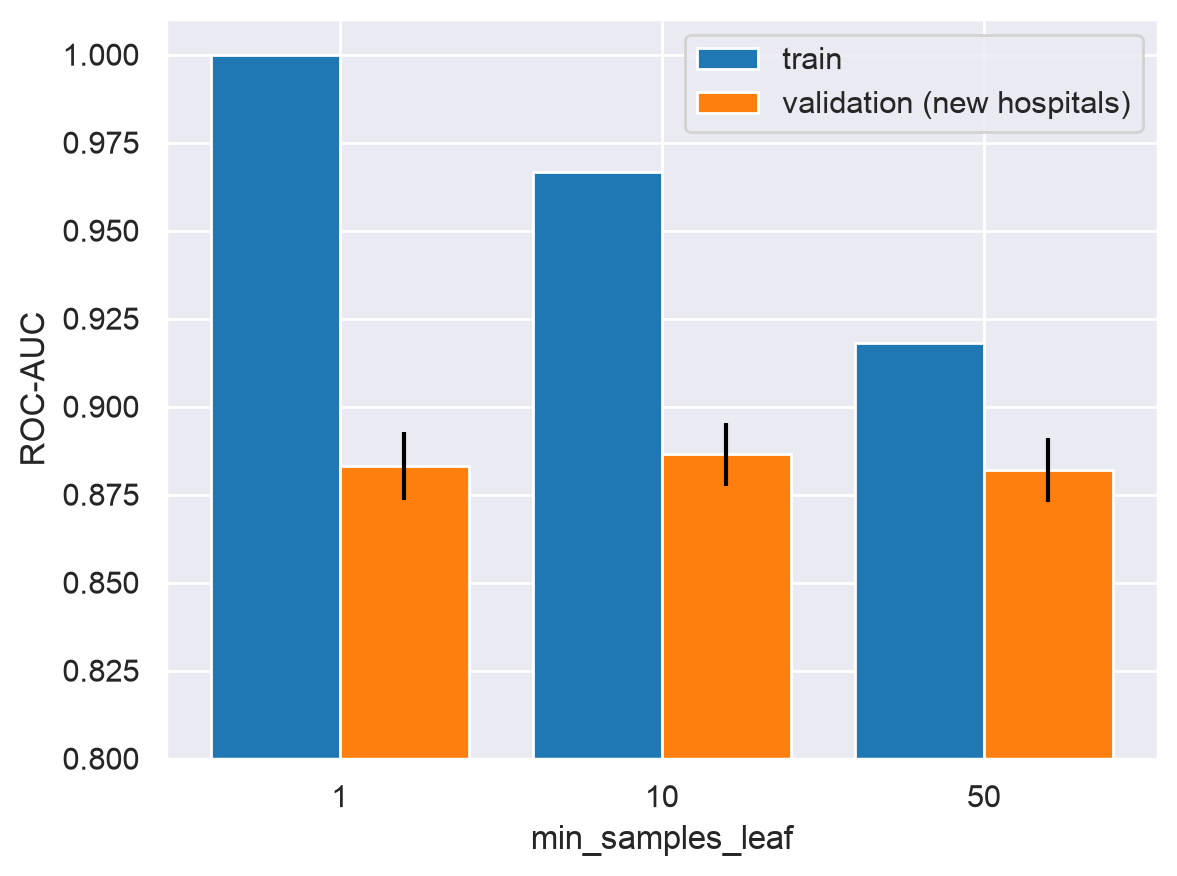

Random forest: train 0.9665 | validation 0.8865 ± 0.0090


In [25]:
# 2. Instantiation
model = ensemble.RandomForestClassifier(
    n_estimators=200, max_samples=0.5, n_jobs=-1, random_state=RANDOM_STATE
)

param_grid = {"min_samples_leaf": [1, 10, 50]}

search = model_selection.GridSearchCV(
    model,
    param_grid,
    scoring=SCORING,
    cv=cv,
    return_train_score=True,
    verbose=1,
)
search.fit(train_xs, train_ys, groups=train_groups)

print(f"Best parameter (CV score: {search.best_score_:.4f})")
print(search.best_params_)

labels = [str(v) for v in param_grid["min_samples_leaf"]]
x = np.arange(len(labels))

plt.bar(
    x - 0.2, search.cv_results_["mean_train_score"], width=0.4, label="train"
)
plt.bar(
    x + 0.2,
    search.cv_results_["mean_test_score"],
    width=0.4,
    yerr=search.cv_results_["std_test_score"],
    label="validation (new hospitals)",
)
plt.xticks(x, labels)
plt.ylim(0.8, 1.01)
plt.xlabel("min_samples_leaf")
plt.ylabel("ROC-AUC")
plt.legend()
plt.show()

rf_model = search.best_estimator_
evaluate("Random forest", rf_model)

### 3.5 LightGBM

[LightGBM](https://lightgbm.readthedocs.io/en/stable/pythonapi/lightgbm.LGBMClassifier.html) is a gradient boosting library: trees are added one at a time, each one correcting the errors of the previous ones. It is the model family used by all the top Kaggle teams, and it handles missing values natively.

We tune `num_leaves`, the size of each tree (4 leaves = a very simple tree of 2 or 3 questions). The grid goes up to 127 so that the best value is not on the edge of the grid.

Fitting 5 folds for each of 5 candidates, totalling 25 fits


Best parameter (CV score: 0.9064)
{'num_leaves': 63}


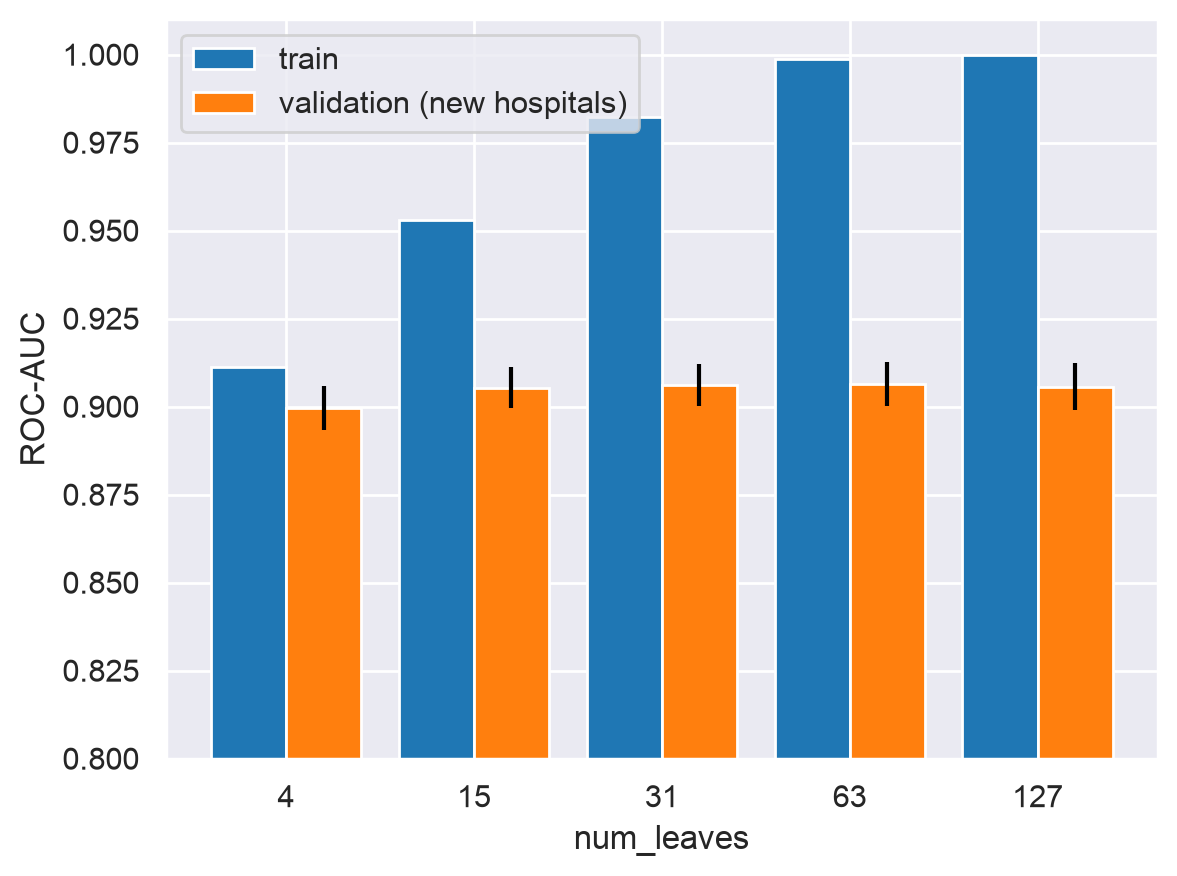

LightGBM: train 0.9987 | validation 0.9064 ± 0.0062


In [26]:
# 2. Instantiation
model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.03,
    colsample_bytree=0.5,  # Each tree sees half of the features
    subsample=0.8,  # Each tree sees 80% of the patients
    subsample_freq=1,
    random_state=RANDOM_STATE,
    verbose=-1,
)

param_grid = {"num_leaves": [4, 15, 31, 63, 127]}

search = model_selection.GridSearchCV(
    model,
    param_grid,
    scoring=SCORING,
    cv=cv,
    return_train_score=True,
    verbose=1,
)
search.fit(train_xs, train_ys, groups=train_groups)

print(f"Best parameter (CV score: {search.best_score_:.4f})")
print(search.best_params_)

labels = [str(v) for v in param_grid["num_leaves"]]
x = np.arange(len(labels))

plt.bar(
    x - 0.2, search.cv_results_["mean_train_score"], width=0.4, label="train"
)
plt.bar(
    x + 0.2,
    search.cv_results_["mean_test_score"],
    width=0.4,
    yerr=search.cv_results_["std_test_score"],
    label="validation (new hospitals)",
)
plt.xticks(x, labels)
plt.ylim(0.8, 1.01)
plt.xlabel("num_leaves")
plt.ylabel("ROC-AUC")
plt.legend()
plt.show()

lgbm_model = search.best_estimator_
evaluate("LightGBM", lgbm_model)

### 3.6 Comparison

,train,validation,validation std,train - validation
Dummy,0.5000,0.5000,0.0000,0.0000
Logistic regression,0.8993,0.8911,0.0071,0.0083
Random forest,0.9665,0.8865,0.0090,0.0801
LightGBM,0.9987,0.9064,0.0062,0.0923


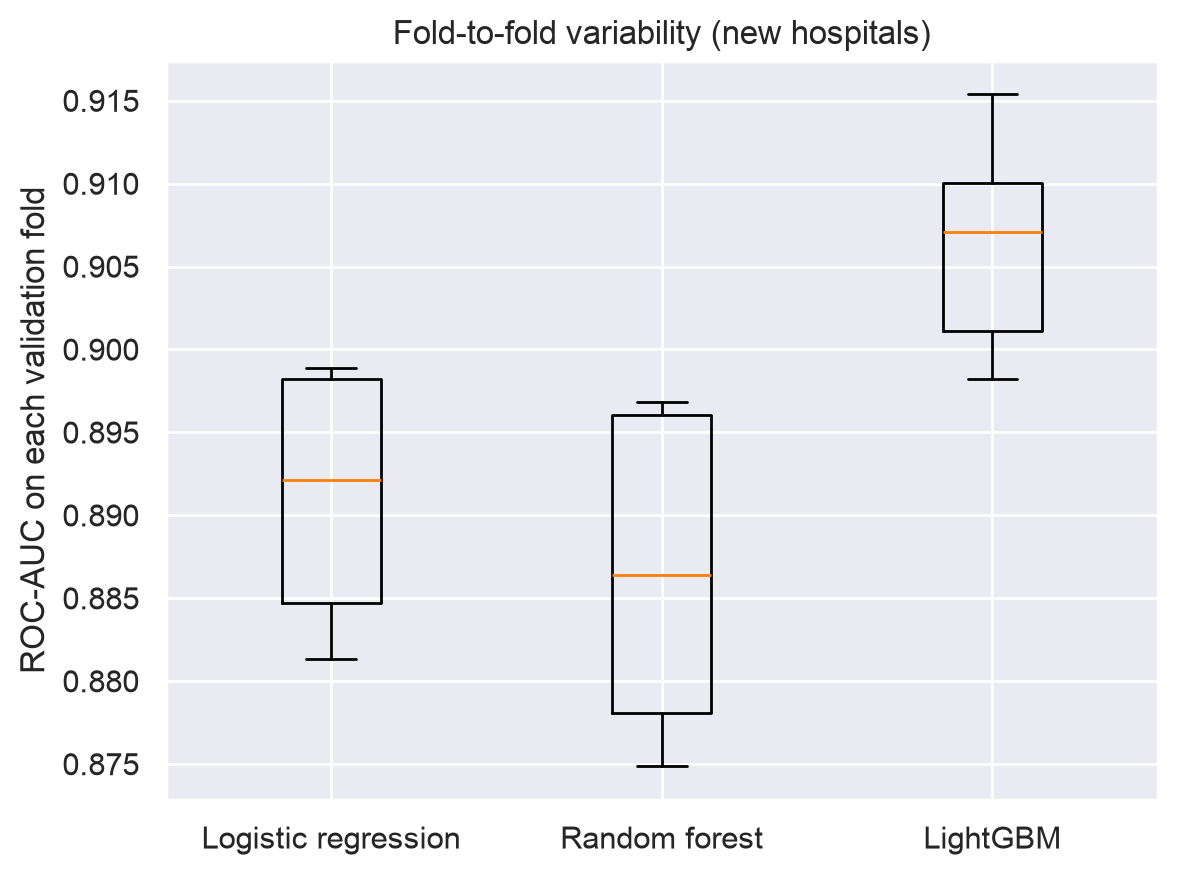

In [27]:
MODELS = ["Dummy", "Logistic regression", "Random forest", "LightGBM"]

summary_df = pd.DataFrame(
    {
        "train": [cv_results[name]["train_score"].mean() for name in MODELS],
        "validation": [
            cv_results[name]["test_score"].mean() for name in MODELS
        ],
        "validation std": [
            cv_results[name]["test_score"].std() for name in MODELS
        ],
    },
    index=MODELS,
)
summary_df["train - validation"] = (
    summary_df["train"] - summary_df["validation"]
)
display(summary_df.round(4))

plt.boxplot([cv_results[name]["test_score"] for name in MODELS[1:]])
plt.xticks([1, 2, 3], MODELS[1:])
plt.ylabel("ROC-AUC on each validation fold")
plt.title("Fold-to-fold variability (new hospitals)")
plt.show()

**Observations**

* We notice that LightGBM is the best model on new hospitals (0.906), followed by the logistic regression (0.891) and the random forest (0.887). The random forest doesn't beat the much simpler logistic regression.

* The variation between folds is about ± 0.006 to 0.009 (boxplot), which is about the size of the spread of the whole Kaggle top 50 (0.005). So differences in the third decimal between models, or between Kaggle teams, are mostly noise.

### 3.7 Overfitting source 1: the training patients

The `train - validation` column of the table above shows how much each model **memorizes its training patients**.

**Observations**

*  The logistic regression has a very small gap between train and validation (0.008). It’s a linear model, so it can only draw one boundary for all the patients: it’s too simple to memorize individual patients, which is why it barely overfits.

* The tree models have a much bigger gap: 0.080 for the random forest and 0.092 for LightGBM. In the grid searches, we notice that when the leaves get smaller (random forest) or the trees get bigger (LightGBM), the training score goes up to almost 1, but the validation score doesn’t follow. For the random forest, with leaves of 1 patient the training score is about 1.000, but the validation (about 0.883) is lower than with leaves of 10 patients (0.887): the trees learn the noise of each training patient. With leaves of 50, both scores go down, because the trees become too simple. For LightGBM, the validation score stops improving after about 31 leaves (around 0.906), while the training score keeps increasing up to 1.000. So the extra complexity is only used to memorize the training patients.

* This is why we never judge a model on its training score: a model that memorizes the patients gets an almost perfect score on them, but that says nothing about new patients. LightGBM overfits the most, but it is still the best model on new hospitals, because it learns useful non-linear patterns in addition to the noise. Only the validation score on new hospitals tells us how good a model really is.

### 3.8 Overfitting source 2: the training hospitals

We compare two ways of splitting the training set:

*   **New hospitals**: `GroupKFold`, as everywhere else

*   **Same hospitals**: [`KFold`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.KFold.html) with shuffling: the validation patients come from hospitals seen in training

We also add `hospital_id` as a feature. With a random split, the model can learn the death rate of each hospital; with a grouped split, the validation hospitals are unknown, so this cannot help.

In [28]:
random_cv = model_selection.KFold(
    n_splits=5, shuffle=True, random_state=RANDOM_STATE
)
train_hosp_xs = train_xs.assign(
    hospital_id=pd.Categorical(train_groups)
)  # A category, so LightGBM can learn one value per hospital

rows = {}
for split_name, split_cv in [
    ("new hospitals", cv),
    ("same hospitals", random_cv),
]:
    for feature_name, xs in [
        ("without hospital_id", train_xs),
        ("with hospital_id", train_hosp_xs),
    ]:
        scores = model_selection.cross_val_score(
            lgbm_model,
            xs,
            train_ys,
            groups=train_groups,
            cv=split_cv,
            scoring=SCORING,
        )
        rows[(split_name, feature_name)] = f"{scores.mean():.4f} ± {scores.std():.4f}"

pd.Series(rows, name="ROC-AUC").unstack()

,with hospital_id,without hospital_id
new hospitals,0.9049 ± 0.0069,0.9064 ± 0.0062
same hospitals,0.9085 ± 0.0059,0.9080 ± 0.0054


**Observations**

* Without `hospital_id`, the score is a bit higher when the validation patients come from the same hospitals (0.9080) than from new hospitals (0.9064). So the random split is more optimistic, but only by 0.0016, which is smaller than the variation between folds (± 0.005 to 0.006).

* With `hospital_id`, the score goes slightly up with the random split (0.9085 instead of 0.9080) and slightly down with the grouped split (0.9049 instead of 0.9064). That’s the direction we expected: knowing the hospital helps a little when the validation patients come from the same hospitals, and hurts a little for a new hospital. But both effects are smaller than 0.002, so again smaller than the ±, and we can’t confidently say they’re real.

* We expected to see the models overfit the training hospitals, but for ranking the patients we see very little of it: the patient signal (lactate, ventilation, Glasgow scores...) seems to work the same way in every hospital. One possible reason `hospital_id` adds so little is that the features already reveal the hospital (Section 3.10), so the model doesn’t need the identifier. We check in Section 4.3 whether the hospitals affect the probabilities instead.

### 3.9 Overfitting source 3: model complexity

Gradient boosting adds trees one at a time. With [`validation_curve`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.validation_curve.html), we follow the training and validation scores as the number of trees grows.

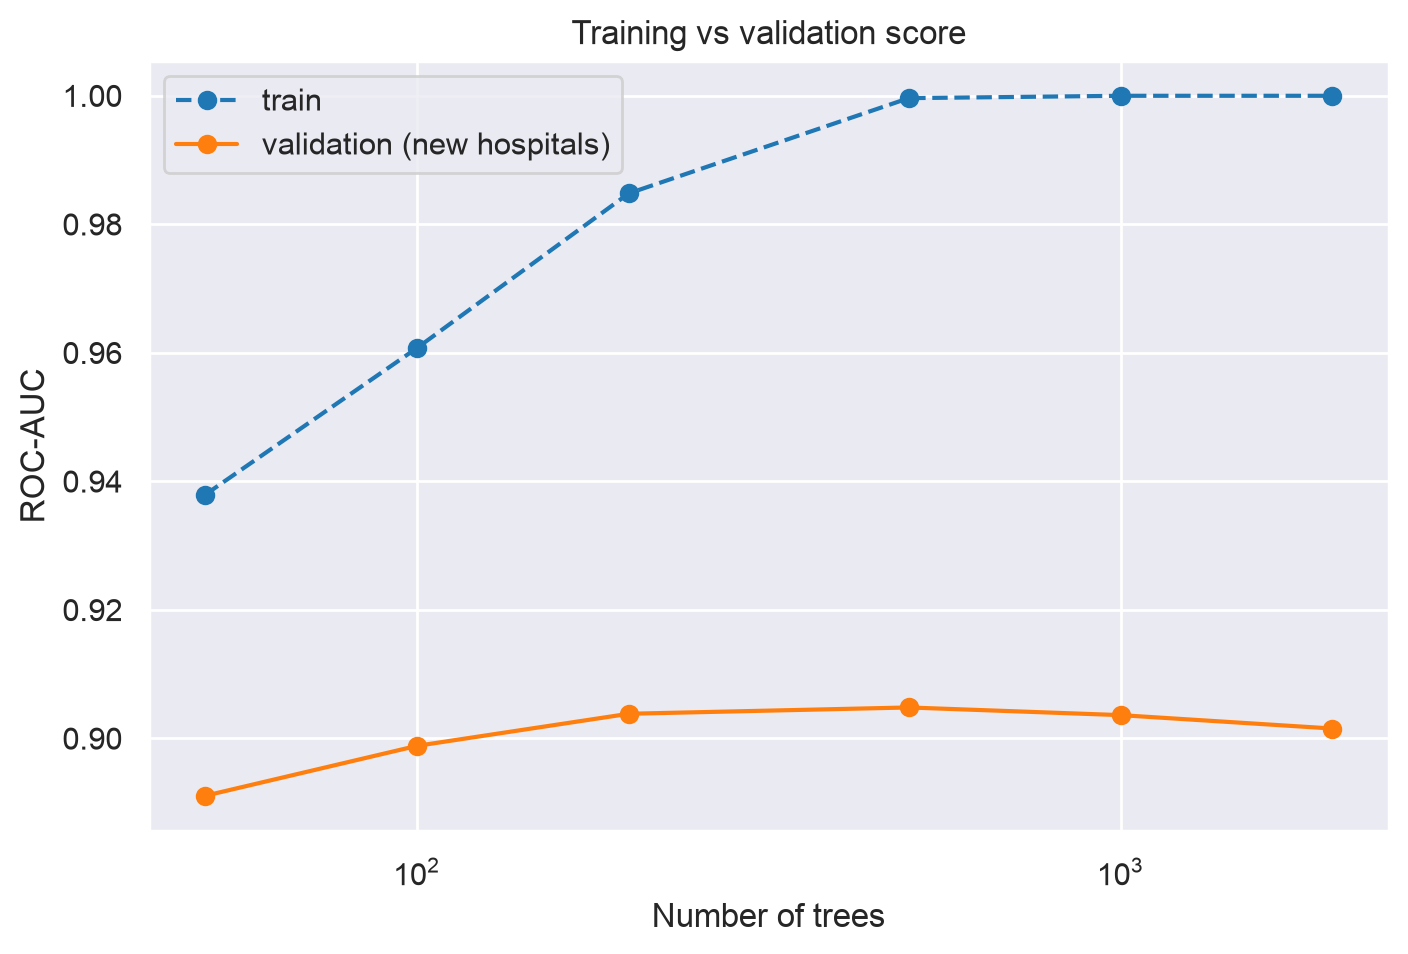

,train,validation
50,0.9379,0.8911
100,0.9608,0.8989
200,0.9848,0.9038
500,0.9996,0.9048
1000,1.0000,0.9036
2000,1.0000,0.9015


In [29]:
N_TREES = [50, 100, 200, 500, 1000, 2000]

train_scores, valid_scores = model_selection.validation_curve(
    lgbm_model,
    train_xs,
    train_ys,
    groups=train_groups,
    param_name="n_estimators",
    param_range=N_TREES,
    cv=model_selection.GroupKFold(n_splits=3),
    scoring=SCORING,
)

plt.figure(figsize=(8, 5))
plt.plot(N_TREES, train_scores.mean(axis=1), "o--", label="train")
plt.plot(
    N_TREES,
    valid_scores.mean(axis=1),
    "o-",
    label="validation (new hospitals)",
)
plt.xscale("log")
plt.xlabel("Number of trees")
plt.ylabel("ROC-AUC")
plt.title("Training vs validation score")
plt.legend()
plt.show()

pd.DataFrame(
    {
        "train": train_scores.mean(axis=1),
        "validation": valid_scores.mean(axis=1),
    },
    index=N_TREES,
).round(4)

**Observations**

* The training score keeps increasing and reaches 1.000 from 1,000 trees: with enough trees, the model memorizes the training patients.

* The validation score increases until 500 trees (0.905), then slowly decreases (0.904 at 1,000 and 0.902 at 2,000): after this point, adding trees only adds overfitting. Our model uses 500 trees, so it is at the best point. We used 3 folds here instead of 5 to save time, since each point means training several models.

### 3.10 Overfitting source 4: hospital "fingerprints" in the features

Removing `hospital_id` does not remove the hospital: each hospital has its own case mix, units and testing habits. If the features reveal *which hospital* a patient comes from, the model can learn hospital-specific shortcuts.

*   **Test 1:** can a classifier recognize the hospital (among the 20 largest) from the features? From the missing-value pattern only (was this measurement taken: yes/no)?

*   **Test 2:** how well does the missing-value pattern alone predict death?

In [30]:
largest = pd.Series(train_groups).value_counts().head(20).index
in_largest = np.isin(train_groups, largest)

hosp_xs = train_xs[in_largest]
hosp_ys = train_groups[in_largest]
missing_xs = hosp_xs.isna().astype(int)  # 1 = the measurement is missing

model = lgb.LGBMClassifier(n_estimators=100, learning_rate=0.1, verbose=-1)
for name, xs in [
    ("all features", hosp_xs),
    ("missing-value pattern only", missing_xs),
]:
    scores = model_selection.cross_val_score(
        model, xs, hosp_ys, cv=3, scoring="accuracy"
    )
    print(f"Hospital recognized from {name}: {scores.mean():.1%}")

pprint_var(
    accuracy_largest_hospital=pd.Series(hosp_ys)
    .value_counts(normalize=True)
    .max()
)

Hospital recognized from all features: 80.6%


Hospital recognized from missing-value pattern only: 41.8%
accuracy_largest_hospital = 0.1074


In [31]:
evaluate(
    "LightGBM on missingness only", lgbm_model, train_xs.isna().astype(int)
)

LightGBM on missingness only: train 0.8513 | validation 0.7645 ± 0.0211


**Observations**

* We notice that the features reveal the hospital: among the 20 largest hospitals, a classifier recognizes the hospital of a patient 80.6% of the time, against 10.7% by always guessing the largest one. Even from the missing-value pattern alone (only “was this measurement taken: yes/no”), it still recognizes the hospital 41.8% of the time. So removing `hospital_id` doesn’t remove the hospital: each hospital leaves a “fingerprint” in the data. This also explains why adding `hospital_id` changed so little in Section 3.8: the model can already recognize the hospital from the features.

* The missing-value pattern alone also predicts death, with a ROC-AUC of 0.765 ± 0.021. That’s better than the best single measured value (0.736 for `d1_lactate_max`, Section 2.5), without knowing any measurement. We think it reflects two things: the clinicians’ judgement (sicker patients get more tests) and the local practices of each hospital (which tests are ordered by default).

* So the model partly relies on how doctors work in each hospital, not only on the patient’s condition. This is why it has to be validated on new hospitals: a hospital with different testing habits could change the model’s performance.

### 3.11 Overfitting source 5: preprocessing fitted on all the data

A common technique on Kaggle is to replace a category by the **death rate of that category** ("target encoding", [`TargetEncoder`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.TargetEncoder.html)). It uses the target, so it must be learnt **on the training folds only**.

We show what happens otherwise with a very fine category: *diagnosis × ICU* (thousands of small groups).

*   **Naive:** the encoder is fitted once on the whole training set, then the usual cross-validation is run

*   **Correct:** the encoder is inside a pipeline, so it is re-fitted on the training folds of each split

In [32]:
diag_icu = (
    icu_df["apache_3j_diagnosis"].astype(str)
    + "_"
    + icu_df["icu_id"].astype(str)
).values[train_idx]
pprint_var(groups=len(set(diag_icu)))

# Naive: fit on all the training set (the validation patients' own outcome is used)
encoder = preprocessing.TargetEncoder(random_state=RANDOM_STATE)
encoder.fit(diag_icu.reshape(-1, 1), train_ys)
naive_xs = train_xs.assign(
    diag_icu_death_rate=encoder.transform(diag_icu.reshape(-1, 1)).ravel()
)

# Correct: the encoder is a step of the pipeline
correct_pipe = pipeline.Pipeline(
    steps=[
        (
            "encoder",
            compose.make_column_transformer(
                (
                    preprocessing.TargetEncoder(random_state=RANDOM_STATE),
                    ["diag_icu"],
                ),
                remainder="passthrough",
            ),
        ),
        ("model", lgbm_model),
    ]
)

evaluate("LightGBM + naive encoding", lgbm_model, naive_xs)
evaluate(
    "LightGBM + correct encoding",
    correct_pipe,
    train_xs.assign(diag_icu=diag_icu),
)

groups = 8784


LightGBM + naive encoding: train 0.9998 | validation 0.9464 ± 0.0010


LightGBM + correct encoding: train 0.9987 | validation 0.9046 ± 0.0071


**Observations**

* We notice that the naive encoding gives a ROC-AUC of 0.946 ± 0.001, which is far above the Kaggle winner (0.915). This score is fake: the encoder was fitted on the whole training set, so each validation patient’s own outcome is included in the death rate of its group. With 8,784 diagnosis × ICU groups, many groups are tiny, so the new feature almost contains the answer. The very small ± (0.001) is also suspicious: the model is “cheating” the same way in every fold.

* Done correctly, inside the pipeline, the same feature gives 0.905 ± 0.007, which is no better than without it (0.906 ± 0.006). With tiny groups, the encoding is mostly noise. Also, since our folds are grouped by hospital, the ICUs of the validation patients were never seen in training, so the encoder can only give them the average death rate.

* The lesson for us is that every step that uses the target must be inside the cross-validation (in a pipeline), so it’s fitted on the training folds only. It’s the same rule as for the PCA in the course. A leak like this one can make a model look better than the state of the art when it’s actually no better at all.

### 3.12 APACHE predictions as features

Same LightGBM, with the two APACHE IVa probabilities added as features.

In [33]:
train_apache_xs = train_xs.join(icu_df[APACHE_PREDICTIONS])
evaluate("LightGBM + APACHE", lgbm_model, train_apache_xs)

LightGBM + APACHE: train 0.9990 | validation 0.9038 ± 0.0071


**Observations**

Adding the APACHE IVa predictions doesn't improve the model (0.9038 with them against 0.9064 without). APACHE is a fixed formula of first-day variables that are already in our features, so it brings no new information. Since our model doesn't use them, it stays independent of the score we compare it to in Section 4.5.

### 3.13 Can simple models get closer to the state of the art with better preprocessing?

Our teacher suggested to approach the state of the art with **simple models and a careful preprocessing**, rather than with large ensembles. We test three ideas:

1.  **Missing-value information:** the "was missing" indicators of the logistic regression (`add_indicator=True` vs `False`), and the `n_missing_values` feature for LightGBM

2.  **Simple clinical features**, the kind a doctor computes by hand from the first-day values:

    *   `gcs_total`: the Glasgow Coma Scale is normally read as the sum eyes + motor + verbal (3 = deep coma, 15 = normal)
    *   `shock_index`: maximum heart rate / minimum systolic blood pressure (above about 1 = sign of shock)
    *   `d1_*_range`: maximum - minimum of five vital signs during the first day (an unstable patient varies a lot)
    *   `n_comorbidities`: number of chronic conditions (cirrhosis, leukemia, ...)

    They don't use the target, so they can be computed once, before the cross-validation.

3.  **Fewer features:** LightGBM using only its 30 most useful features. The selection ([`SelectFromModel`](https://scikit-learn.org/stable/modules/generated/sklearn.feature_selection.SelectFromModel.html)) is a step of the pipeline, so it is redone on the training folds of each split (same rule as in Section 3.11)

In [34]:
lr_no_indicator = base.clone(lr_model).set_params(imputer__add_indicator=False)
evaluate("Logistic regression, no missing indicators", lr_no_indicator)

evaluate(
    "LightGBM, no n_missing_values",
    lgbm_model,
    train_xs.drop(columns="n_missing_values"),
)

Logistic regression, no missing indicators: train 0.8948 | validation 0.8873 ± 0.0081


LightGBM, no n_missing_values: train 0.9986 | validation 0.9057 ± 0.0064


In [35]:
COMORBIDITIES = [
    "aids",
    "cirrhosis",
    "diabetes_mellitus",
    "hepatic_failure",
    "immunosuppression",
    "leukemia",
    "lymphoma",
    "solid_tumor_with_metastasis",
]


# Simple features a clinician computes by hand (no target used)
def add_clinical_features(xs):
    xs = xs.copy()
    gcs = ["gcs_eyes_apache", "gcs_motor_apache", "gcs_verbal_apache"]
    xs["gcs_total"] = xs[gcs].sum(axis=1, min_count=3)  # NaN if a part is missing
    xs["shock_index"] = xs["d1_heartrate_max"] / xs["d1_sysbp_min"]
    for vital in ["heartrate", "sysbp", "resprate", "temp", "spo2"]:
        xs[f"d1_{vital}_range"] = xs[f"d1_{vital}_max"] - xs[f"d1_{vital}_min"]
    xs["n_comorbidities"] = xs[COMORBIDITIES].sum(axis=1)
    return xs


clinical_xs = add_clinical_features(train_xs)

evaluate("Logistic regression + clinical features", lr_model, clinical_xs)
evaluate("LightGBM + clinical features", lgbm_model, clinical_xs)

Logistic regression + clinical features: train 0.8996 | validation 0.8913 ± 0.0072


LightGBM + clinical features: train 0.9988 | validation 0.9063 ± 0.0063


In [36]:
# LightGBM on its 30 most useful features, the selection being redone in each fold
selection_pipe = pipeline.Pipeline(
    steps=[
        (
            "select",
            feature_selection.SelectFromModel(
                lgb.LGBMClassifier(
                    n_estimators=200, random_state=RANDOM_STATE, verbose=-1
                ),
                max_features=30,
                threshold=-np.inf,  # Keep exactly the 30 best
            ),
        ),
        ("model", lgbm_model),
    ]
)
evaluate("LightGBM, 30 features", selection_pipe)

LightGBM, 30 features: train 0.9923 | validation 0.8742 ± 0.0084


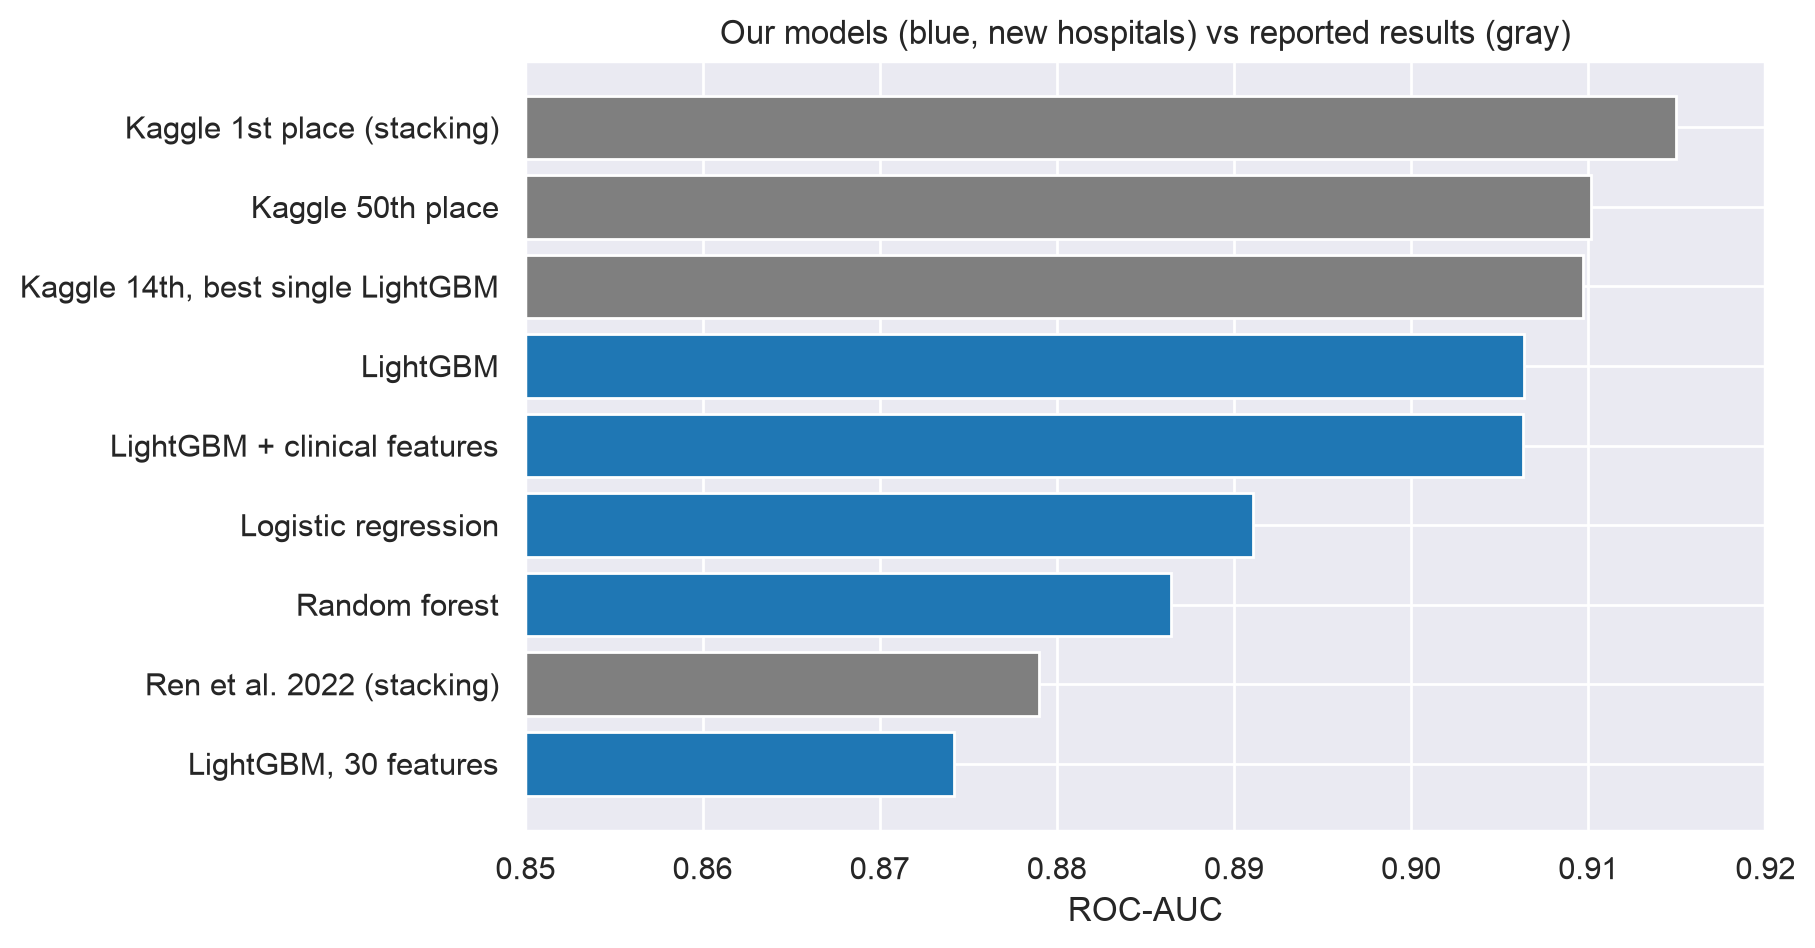

In [37]:
reference = pd.Series(
    {
        "Kaggle 1st place (stacking)": 0.91497,
        "Kaggle 50th place": 0.91013,
        "Kaggle 14th, best single LightGBM": 0.9097,
        "Ren et al. 2022 (stacking)": 0.879,
    }
)
ours = pd.Series(
    {
        name: cv_results[name]["test_score"].mean()
        for name in [
            "Logistic regression",
            "Random forest",
            "LightGBM",
            "LightGBM + clinical features",
            "LightGBM, 30 features",
        ]
    }
)
comparison = pd.concat([ours, reference]).sort_values()

plt.figure(figsize=(8, 5))
colors = [
    "tab:gray" if name in reference.index else "tab:blue"
    for name in comparison.index
]
plt.barh(comparison.index, comparison.values, color=colors)
plt.xlim(0.85, 0.92)
plt.xlabel("ROC-AUC")
plt.title("Our models (blue, new hospitals) vs reported results (gray)")
plt.show()

**Observations**

* We notice that the missing indicators help the logistic regression: 0.891 with them against 0.887 without (+0.004). It’s the biggest gain of all our preprocessing tests, but it’s still a bit smaller than the variation between folds (± 0.007), so it’s a hint more than a proof. It makes sense, though: without the indicators, an imputed median looks like a “normal” value, and the model loses the information that the test wasn’t ordered. For LightGBM, `n_missing_values` barely changes anything (0.9064 with it, 0.9057 without, +0.0007), probably because LightGBM already handles the missing values natively and can see them by itself.

* The clinical features don’t help either model: 0.8913 against 0.8911 for the logistic regression, and 0.9063 against 0.9064 for LightGBM. In theory a linear model should gain more from them, because it can’t build combinations of features by itself, while trees can approximate them. But most of our features are sums or differences of existing columns (`gcs_total`, the first-day ranges, `n_comorbidities`), and a linear model can already build those with its coefficients. Only `shock_index` (a ratio) is really new, and it’s not enough to change the score. So the information was already in the raw features.

* With only its 30 most useful features, LightGBM drops to 0.874 ± 0.008, so we lose 0.032. The information is spread over many features, and keeping only the most important ones removes a lot of small but useful signals.

* Compared with the state of the art, our best single model (LightGBM, 0.906 on new hospitals) is only 0.003 below the best single LightGBM reported on Kaggle (0.9097). That one used more than 700 features and a random split, which is more optimistic. We’re about 0.009 below the winner’s stack (0.915), but that score was measured on a different test set, so the two aren’t directly comparable. Both differences are about the size of our variation between folds, so a simple model with a careful validation gets close to the state of the art.

## 4. Evaluation on unseen hospitals

The models are now re-trained on the **whole training set** and evaluated **once** on the test hospitals.

### 4.1 Test scores

In [38]:
final_models = {
    "Logistic regression": lr_model,
    "Random forest": rf_model,
    "LightGBM": lgbm_model,
}

test_prob_ys = {}
rows = {}
for name, model in final_models.items():
    # 3. Learn (fit) the model
    model.fit(train_xs, train_ys)
    # 4. Predict on new data
    test_prob_ys[name] = model.predict_proba(test_xs)[:, 1]
    rows[name] = {
        "train ROC-AUC": metrics.roc_auc_score(
            train_ys, model.predict_proba(train_xs)[:, 1]
        ),
        "CV ROC-AUC": cv_results[name]["test_score"].mean(),
        "test ROC-AUC": metrics.roc_auc_score(test_ys, test_prob_ys[name]),
        "test PR-AUC": metrics.average_precision_score(
            test_ys, test_prob_ys[name]
        ),
        "test Brier": metrics.brier_score_loss(test_ys, test_prob_ys[name]),
    }

pd.DataFrame(rows).T.round(4)

,train ROC-AUC,CV ROC-AUC,test ROC-AUC,test PR-AUC,test Brier
Logistic regression,0.8989,0.8911,0.8820,0.5282,0.0664
Random forest,0.9667,0.8865,0.8763,0.5312,0.0671
LightGBM,0.9964,0.9064,0.8965,0.5773,0.0627


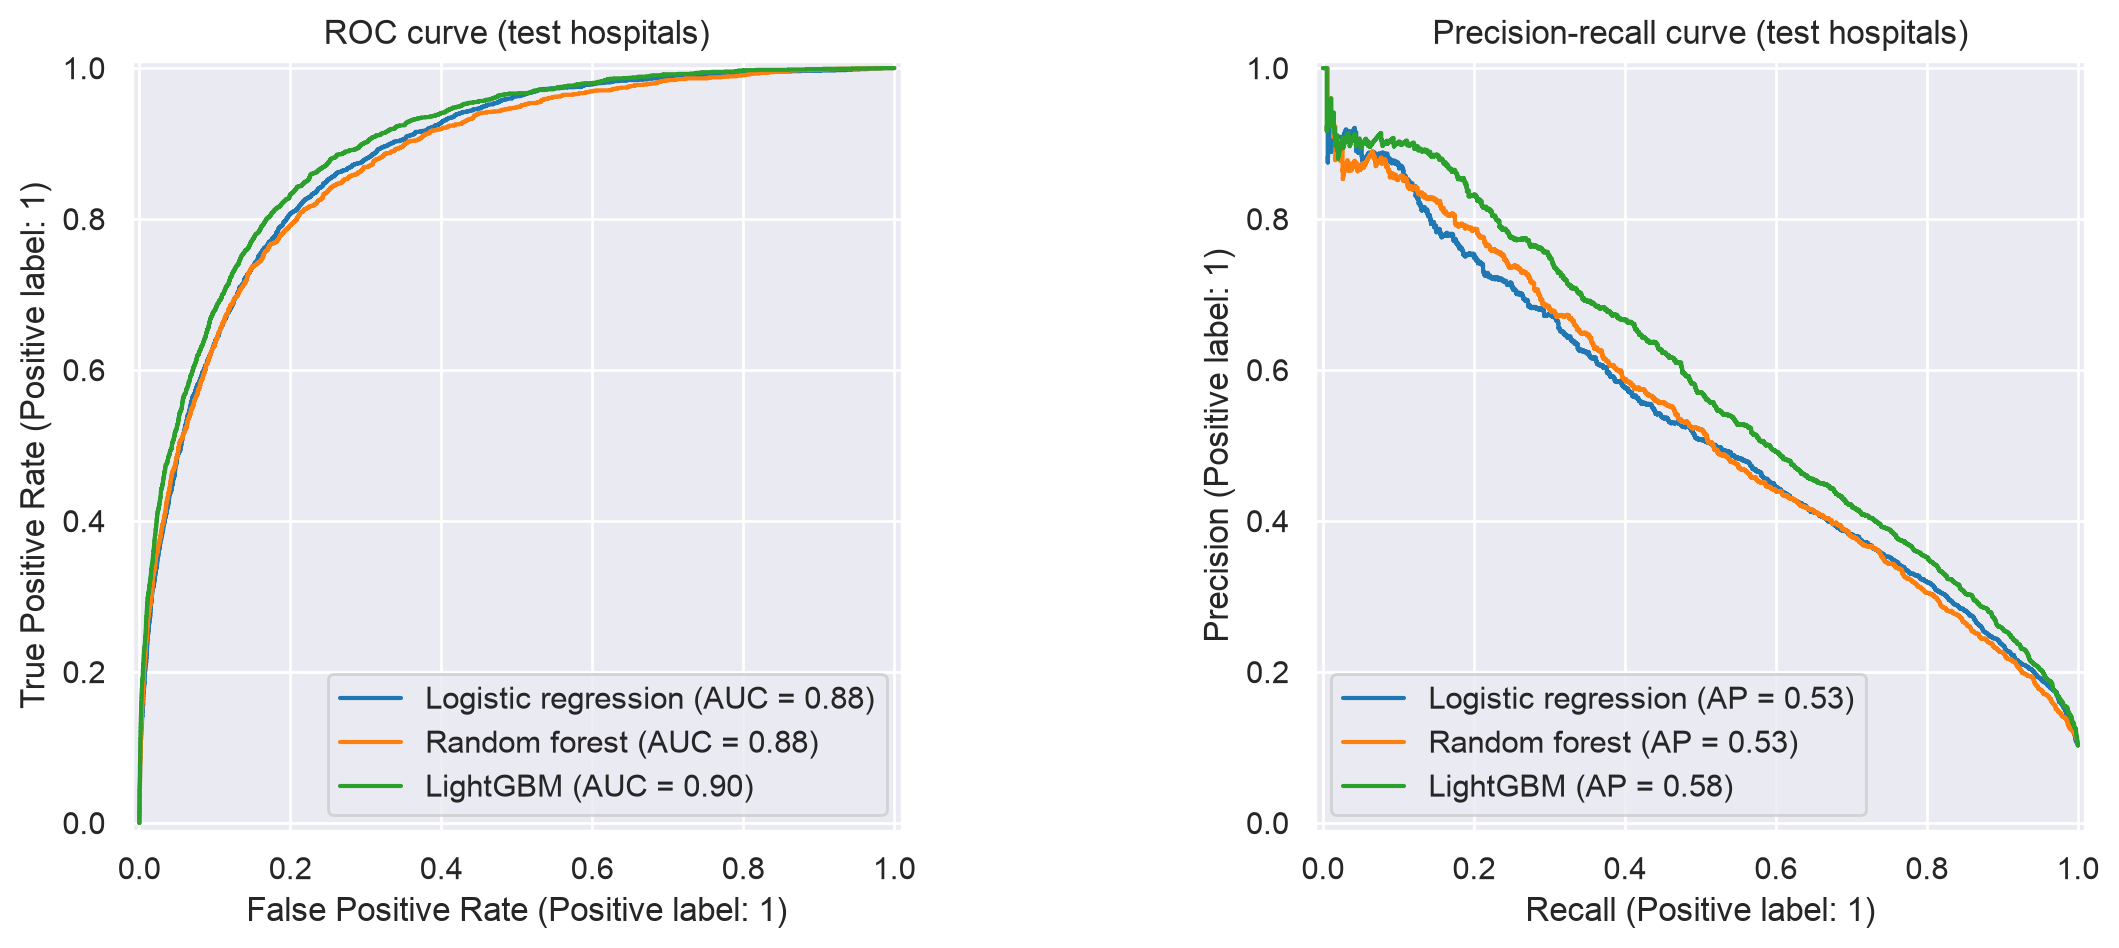

In [39]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for name, model in final_models.items():
    metrics.RocCurveDisplay.from_estimator(
        model, test_xs, test_ys, name=name, ax=ax[0]
    )
    metrics.PrecisionRecallDisplay.from_estimator(
        model, test_xs, test_ys, name=name, ax=ax[1]
    )
ax[0].set(title="ROC curve (test hospitals)")
ax[1].set(title="Precision-recall curve (test hospitals)")
plt.show()

**Observations**

* We can see that LightGBM is the best model on the test hospitals too: ROC-AUC 0.897 and PR-AUC 0.577, against 0.882 and 0.528 for the logistic regression and 0.876 and 0.531 for the random forest. The chance level for the PR-AUC is the test death rate (0.103), so LightGBM is more than 5 times above chance. The order of the models is the same as in the cross-validation, which means our choices on the training hospitals still hold on new ones.

* All the models lose some performance from the training set to the cross-validation to the test set. The trees have the largest gap between train and test (LightGBM: 0.996 → 0.897, random forest: 0.967 → 0.876, against 0.899 → 0.882 for the logistic regression). They overfit the most, but LightGBM still generalizes best.

* The test score is lower than the CV estimate for all three models, by about 0.01 (LightGBM: 0.906 in CV, 0.897 on test). We think there are two reasons. Choosing the best settings on the same validation folds makes the CV score a bit optimistic. And the test hospitals are a different sample, with a higher death rate than the training ones (Section 2.9). The drop is about the size of the variation between folds, so it’s not a sign that something went wrong.

### 4.2 Decision threshold

**Clinical goal (our assumption):** the model is a *screening* tool that flags patients for a closer review. Missing a patient who will die is worse than reviewing a patient who survives, so we want to **catch at least 80% of the deaths** (recall ≥ 0.80).

The threshold is chosen on the **training set**, with out-of-fold predictions ([`cross_val_predict`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html)): each training patient is predicted by a model that did not see their hospital.

In [40]:
TARGET_RECALL = 0.80

oof_prob_ys = model_selection.cross_val_predict(
    lgbm_model,
    train_xs,
    train_ys,
    groups=train_groups,
    cv=cv,
    method="predict_proba",
)[:, 1]

precision, recall, thresholds = metrics.precision_recall_curve(
    train_ys, oof_prob_ys
)
threshold = thresholds[
    recall[:-1] >= TARGET_RECALL
].max()  # Highest threshold with recall >= 80%
pprint_var(threshold=threshold)

threshold = 0.06612


              precision    recall  f1-score   support

    survived       0.98      0.81      0.88     19250
        died       0.33      0.82      0.47      2202

    accuracy                           0.81     21452
   macro avg       0.65      0.82      0.68     21452
weighted avg       0.91      0.81      0.84     21452

alert_rate = 0.2572


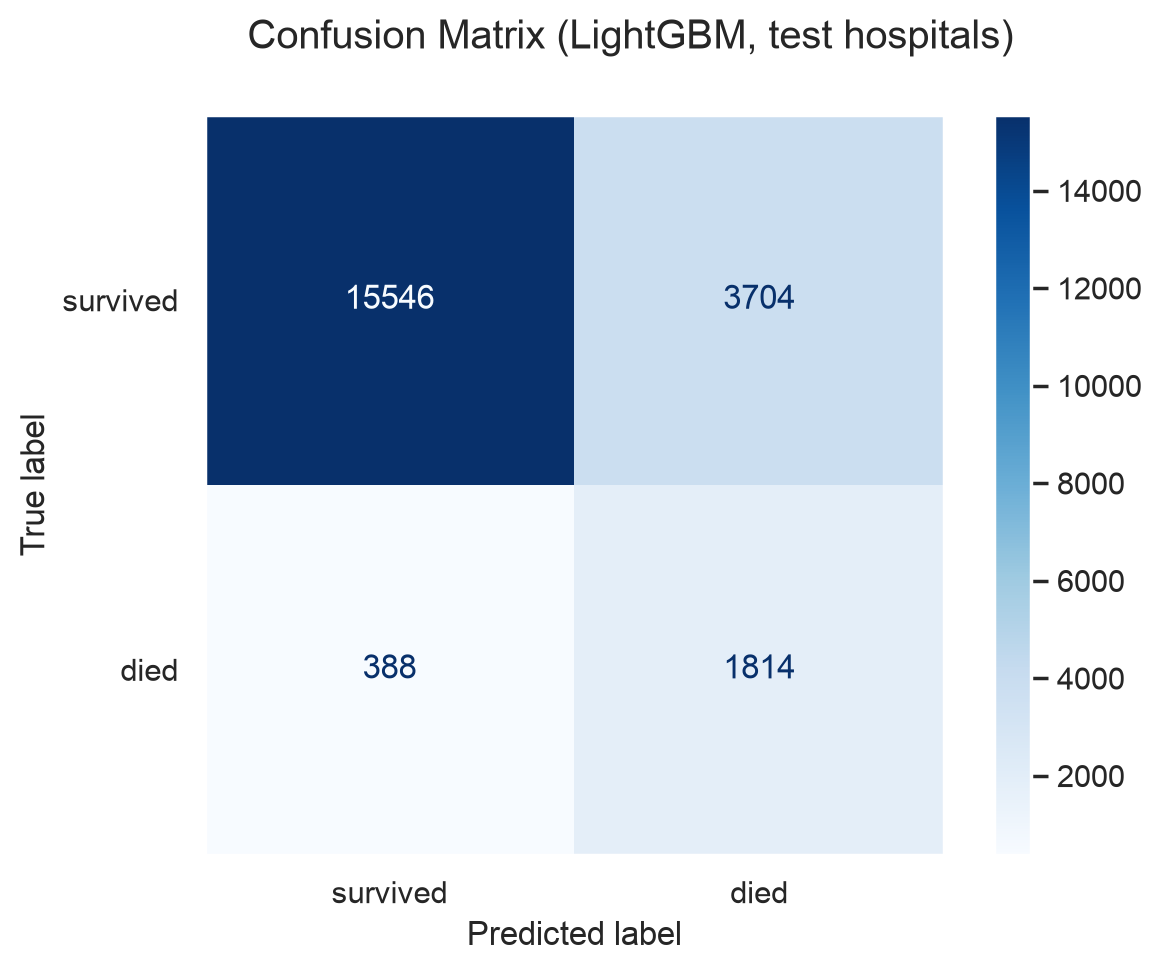

In [41]:
pred_ys = test_prob_ys["LightGBM"] >= threshold

print(
    metrics.classification_report(
        test_ys, pred_ys, target_names=["survived", "died"]
    )
)
pprint_var(alert_rate=pred_ys.mean())

disp = metrics.ConfusionMatrixDisplay.from_predictions(
    test_ys, pred_ys, display_labels=["survived", "died"], cmap=plt.cm.Blues
)
disp.figure_.suptitle("Confusion Matrix (LightGBM, test hospitals)")
plt.grid(False)
plt.show()

**Observations**

* The threshold (0.066) was chosen on the training hospitals, with out-of-fold predictions, and it transfers well to the new hospitals: the recall of the deaths on the test set is 0.82, a bit above our target of 0.80.

* The price is an alert for 25.7% of the patients, with a precision of 0.33: about 1 alert in 3 is a patient who will die, against about 1 in 10 if we flagged patients at random (the test death rate is 10.3%). The threshold is low (0.066) because deaths are rare: to catch 80% of them, we have to flag patients whose risk is only a little above average.

* The accuracy (0.81) is lower than what “always survives” would get on the test hospitals (0.897). This is expected, since we accept false alarms to catch more deaths, and it confirms that the accuracy is not the right metric here.

### 4.3 Calibration

A calibration curve groups the patients by predicted risk and plots the observed death rate in each group ([`CalibrationDisplay`](https://scikit-learn.org/stable/modules/generated/sklearn.calibration.CalibrationDisplay.html)). Points on the diagonal mean that the probabilities can be read literally ("30% risk" = 30% of such patients die).

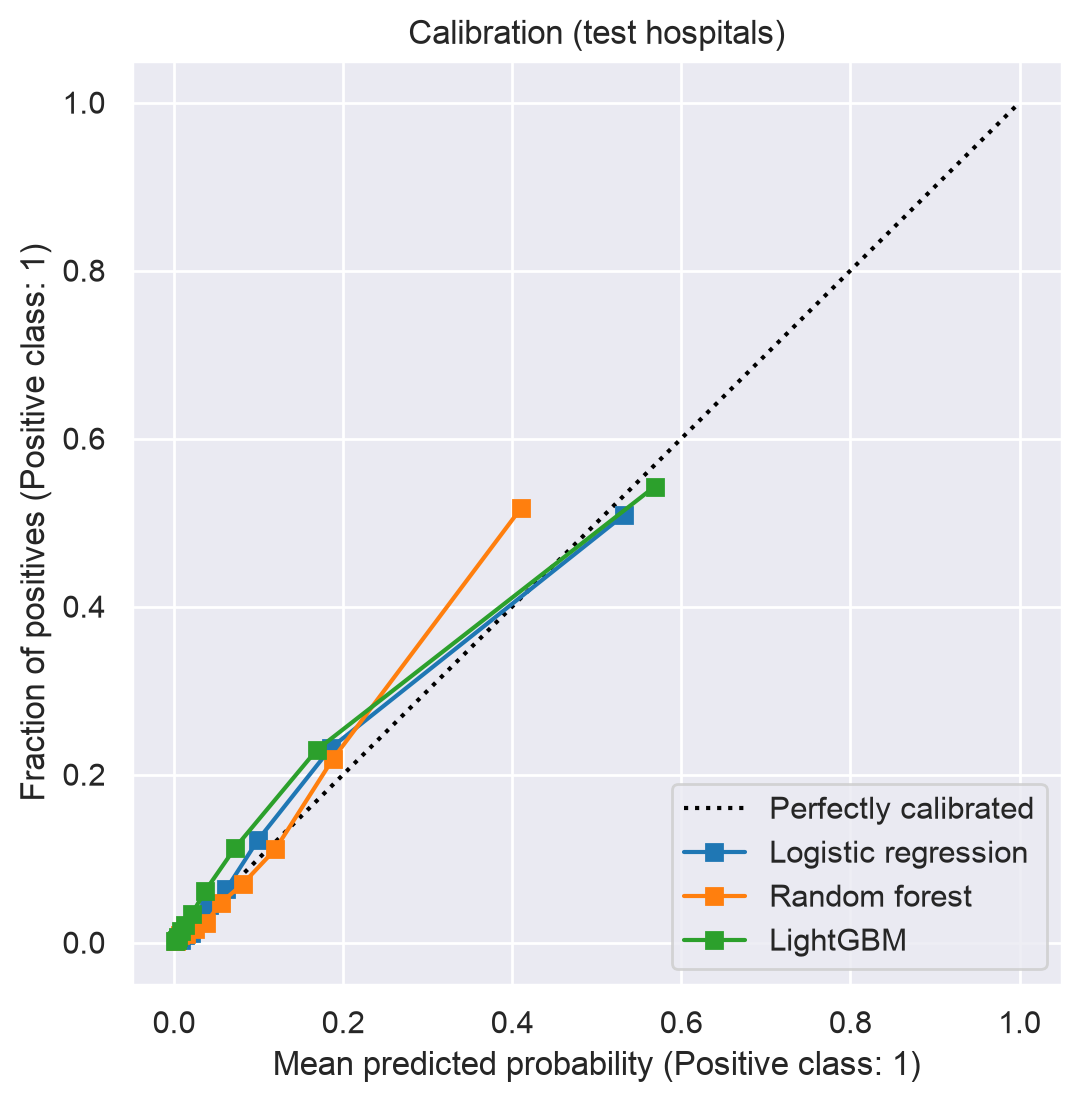

In [42]:
fig, ax = plt.subplots(figsize=(6, 6))
for name in final_models:
    calibration.CalibrationDisplay.from_predictions(
        test_ys,
        test_prob_ys[name],
        n_bins=10,
        strategy="quantile",
        name=name,
        ax=ax,
    )
ax.set(title="Calibration (test hospitals)")
plt.show()

**Observations**

The three curves are close to the diagonal, so the probabilities are roughly usable as they are. The logistic regression is the closest. LightGBM’s points are mostly slightly above the diagonal: for example, patients with a predicted risk of about 7% actually die about 11% of the time, so it under-estimates the risk a little. The random forest is close for most patients but under-estimates the sickest ones (about 0.41 predicted against 0.52 observed in the highest-risk group), because averaging many trees pulls the probabilities towards the middle. LightGBM still has the best Brier score (0.063 against 0.066 for the logistic regression and 0.067 for the random forest), because it ranks the patients better, even if its probabilities are a bit too low.

#### Do the probabilities transfer to new hospitals?

Section 3.8 compared the **ranking** of the patients between the same and new hospitals. Here we check the **probabilities**: on average, does the model predict the right death rate for hospitals it has never seen?

In [43]:
# Out-of-fold predictions: each training patient predicted by a model that did not see their hospital
lr_oof_prob_ys = model_selection.cross_val_predict(
    lr_model, train_xs, train_ys, groups=train_groups, cv=cv, method="predict_proba"
)[:, 1]

pd.DataFrame(
    {
        "observed mortality": [train_ys.mean(), test_ys.mean()],
        "mean predicted risk (LightGBM)": [
            oof_prob_ys.mean(),  # From Section 4.2
            test_prob_ys["LightGBM"].mean(),
        ],
        "mean predicted risk (logistic regression)": [
            lr_oof_prob_ys.mean(),
            test_prob_ys["Logistic regression"].mean(),
        ],
    },
    index=["training hospitals", "test hospitals"],
).round(4)

,observed mortality,mean predicted risk (LightGBM),mean predicted risk (logistic regression)
training hospitals,0.0813,0.0703,0.0807
test hospitals,0.1026,0.0898,0.0994


**Observations**

* This answers the question from Section 2.9. The test hospitals have a higher death rate than the training ones (0.103 against 0.081), and the mean predicted risk of the logistic regression follows it: 0.081 in training, 0.099 in test. So the model “saw” from the features alone (lactate, ventilation, Glasgow scores...) that the test patients were sicker, which supports our first theory: the extra deaths are mostly explained by sicker patients, not by the hospitals themselves.

* LightGBM also follows the increase (0.070 → 0.090), but it under-estimates the risk by about 13% in both the training and the test hospitals. Since the gap is the same in both, it doesn’t come from the new hospitals but from the model itself. It’s probably linked to its overfitting (training ROC-AUC 0.999, Sections 3.7 and 3.9), which makes its predictions too confident.

* Before trusting the probabilities, a new hospital should still check the calibration on some of its own patients (for example a few months of data) and, if needed, recalibrate the model, which adjusts the probabilities without changing how the patients are ranked. For LightGBM, a recalibration would also fix the under-estimation we see here.

### 4.4 Most important features

*   For LightGBM: `feature_importances_` with `importance_type="gain"` = how much each feature improved the trees in total

*   For the logistic regression: the coefficients $a_j$ of the standardized features, as in the course (positive = higher risk)

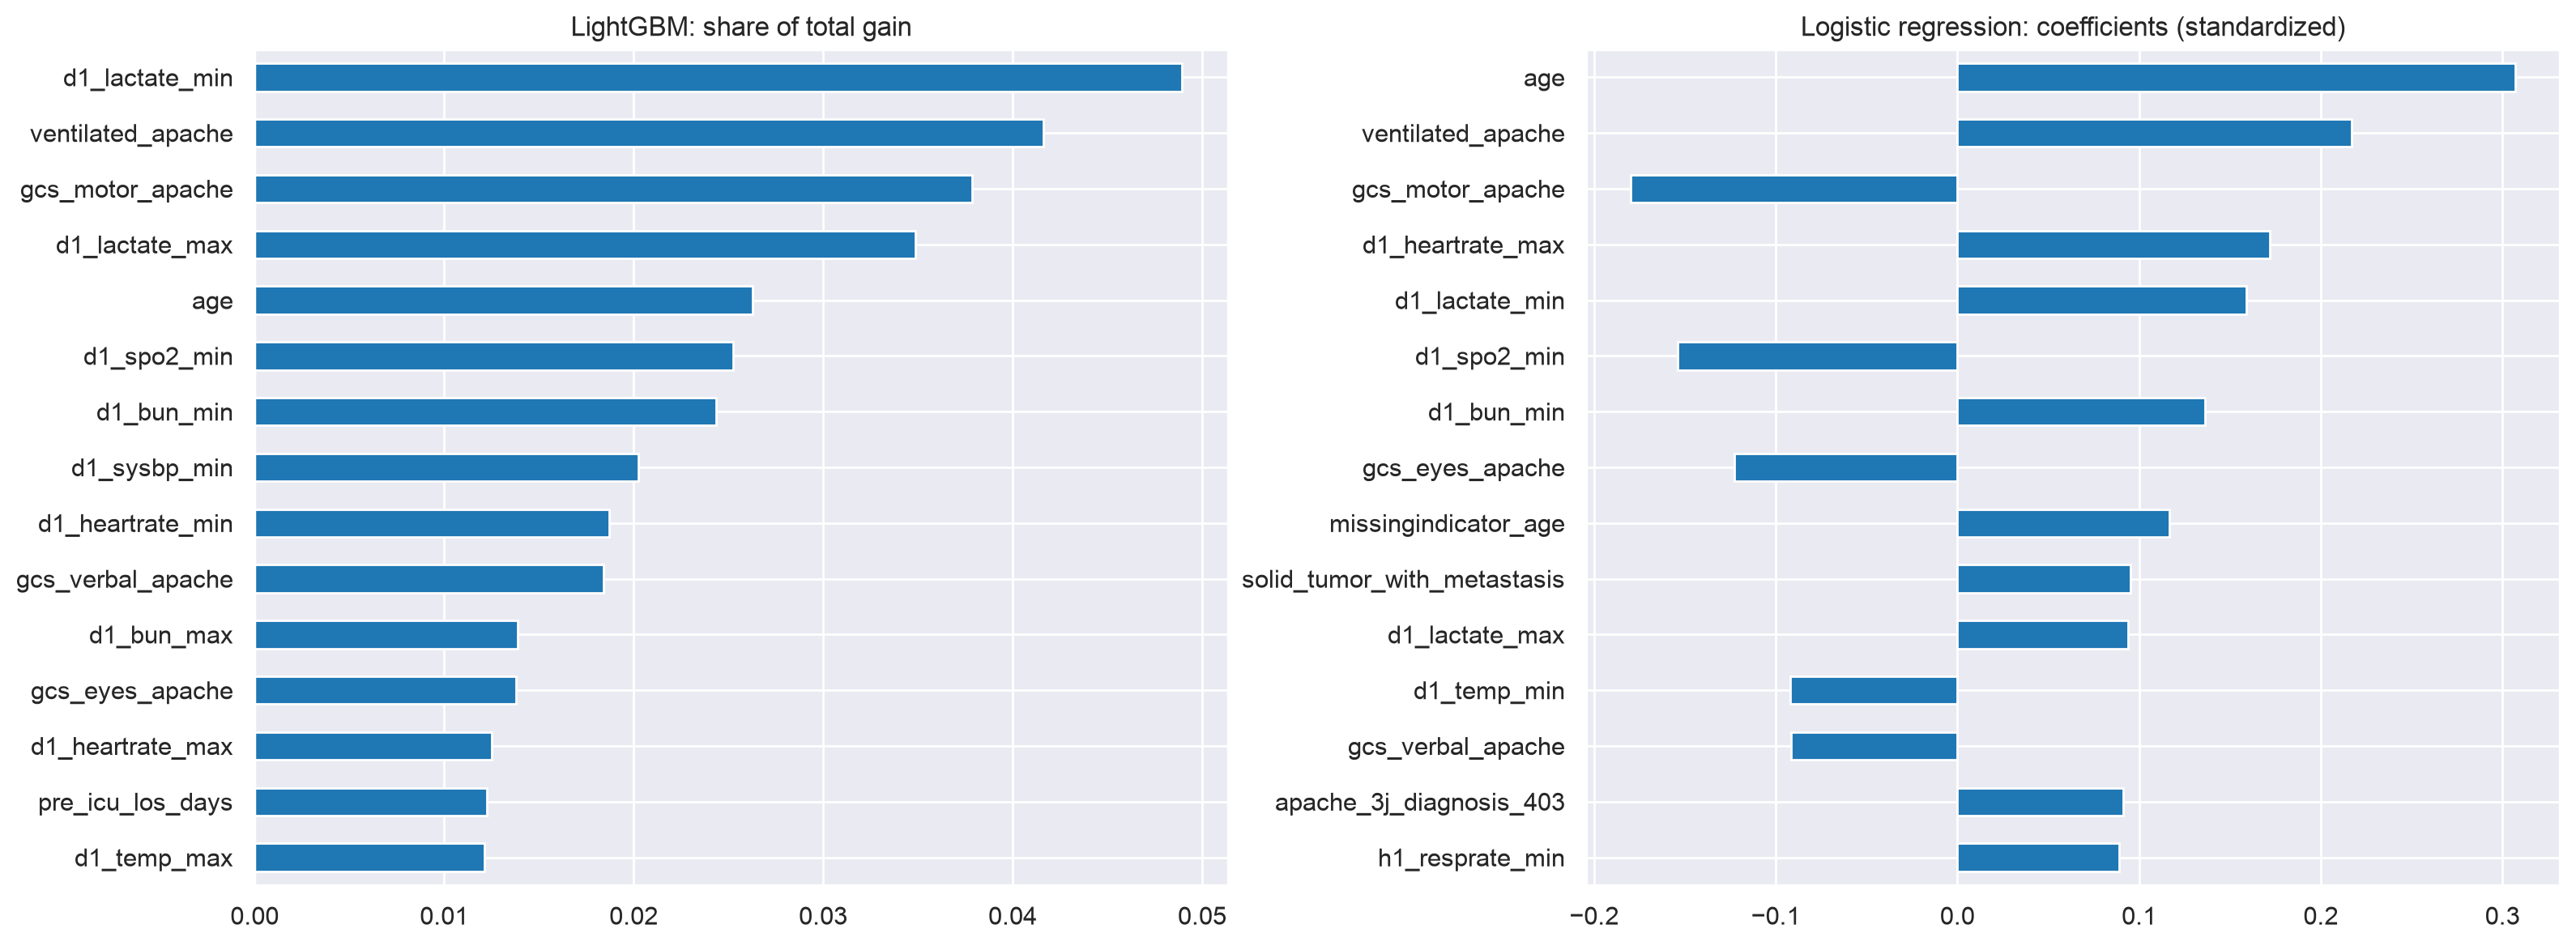

In [44]:
lgbm_importance = pd.Series(
    lgbm_model.booster_.feature_importance(importance_type="gain"),
    index=train_xs.columns,
)
lgbm_importance = lgbm_importance / lgbm_importance.sum()

lr_coefs = pd.Series(
    lr_model.named_steps["model"].coef_[0],
    index=lr_model.named_steps["imputer"].get_feature_names_out(),
)

fig, ax = plt.subplots(1, 2, figsize=(16, 6))
lgbm_importance.nlargest(15).sort_values().plot.barh(ax=ax[0])
ax[0].set(title="LightGBM: share of total gain", xlabel="")
lr_coefs.sort_values(key=abs).tail(15).plot.barh(ax=ax[1])
ax[1].set(title="Logistic regression: coefficients (standardized)", xlabel="")
plt.tight_layout()
plt.show()

**Observations**

* We notice that both models mostly use the same features, and they are clinically sensible: lactate (poor oxygen supply to the tissues), mechanical ventilation, the Glasgow scores (consciousness), age, oxygen saturation, urea (kidney function), blood pressure and heart rate. The signs of the logistic regression coefficients also make sense: an older patient, a ventilated patient, a higher lactate, urea or heart rate increase the risk, while a higher Glasgow score or oxygen saturation decrease it. Metastatic cancer (`solid_tumor_with_metastasis`) also appears as a risk factor.

* Two things surprised us. First, the diagnosis doesn’t appear in LightGBM’s top features, although it’s important medically. We think it’s because the one-hot encoding splits it into more than 100 columns, so its importance is spread over many small columns. Second, `missingindicator_age` has a positive coefficient: patients whose age is missing have a higher risk. We’re not sure why; it could be patients admitted in an emergency before their details were recorded.

**Note:** as in the course, correlated features share their importance, and an important feature is not necessarily a *cause* of death.

### 4.5 Comparison with APACHE IVa

APACHE IVa is the score already used in hospitals. We compare it with our model on the test patients that have an APACHE score: discrimination, number of alerts needed to catch 80% of the deaths, and calibration.

APACHE IVa   ROC-AUC 0.8561 | recall 0.827 | alert rate 0.336
LightGBM     ROC-AUC 0.8980 | recall 0.818 | alert rate 0.251


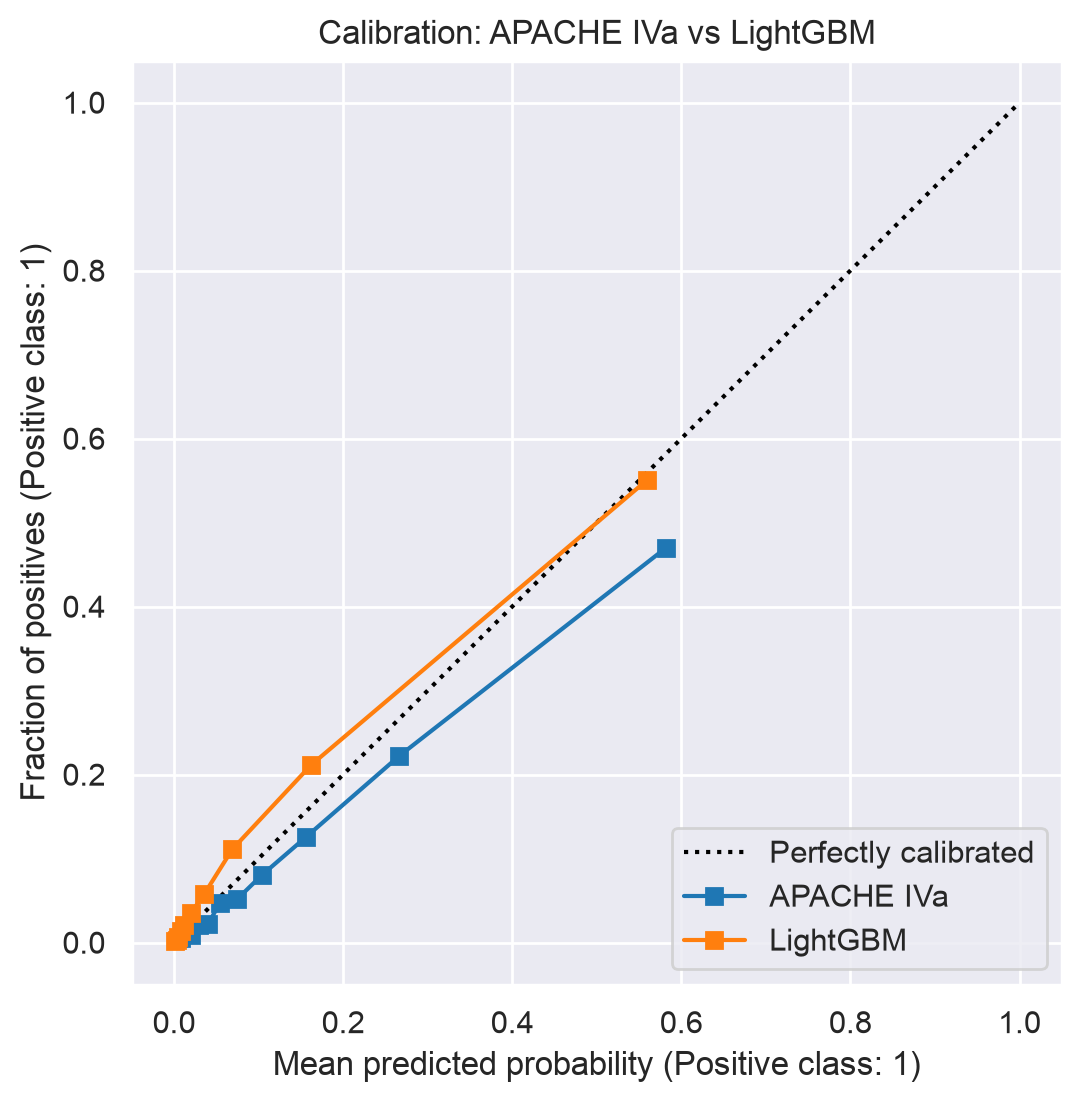

In [45]:
test_apache_ys = icu_df[APACHE_PREDICTIONS[0]].values[test_idx]
has_score = ~np.isnan(test_apache_ys)

train_apache_ys = icu_df[APACHE_PREDICTIONS[0]].values[train_idx]
train_has_score = ~np.isnan(train_apache_ys)
_, apache_recall, apache_thresholds = metrics.precision_recall_curve(
    train_ys[train_has_score], train_apache_ys[train_has_score]
)
apache_threshold = apache_thresholds[apache_recall[:-1] >= TARGET_RECALL].max()

for name, prob_ys, thr in [
    ("APACHE IVa", test_apache_ys[has_score], apache_threshold),
    ("LightGBM", test_prob_ys["LightGBM"][has_score], threshold),
]:
    alerts = prob_ys >= thr
    print(
        f"{name:12s} ROC-AUC {metrics.roc_auc_score(test_ys[has_score], prob_ys):.4f} | recall {metrics.recall_score(test_ys[has_score], alerts):.3f} | alert rate {alerts.mean():.3f}"
    )

fig, ax = plt.subplots(figsize=(6, 6))
calibration.CalibrationDisplay.from_predictions(
    test_ys[has_score],
    test_apache_ys[has_score],
    n_bins=10,
    strategy="quantile",
    name="APACHE IVa",
    ax=ax,
)
calibration.CalibrationDisplay.from_predictions(
    test_ys[has_score],
    test_prob_ys["LightGBM"][has_score],
    n_bins=10,
    strategy="quantile",
    name="LightGBM",
    ax=ax,
)
ax.set(title="Calibration: APACHE IVa vs LightGBM")
plt.show()

**Observations**

* On the same test patients, our LightGBM ranks the patients better than APACHE IVa: ROC-AUC 0.898 against 0.856.

* To catch about 80% of the deaths, APACHE alerts 33.6% of the patients, while our model alerts only 25.1%, so about 8 fewer alerts per 100 patients.

* APACHE over-estimates the risk (its points are below the diagonal). This may be because it’s a fixed formula developed on another population and at another time. Our model is closer to the diagonal.

### 4.6 Errors, hospitals and subgroups

*   **Missed deaths:** how do the deaths that the model missed (false negatives) differ from the detected ones?

*   **Per hospital:** is the model as good in every test hospital?

*   **Subgroups:** is the model as good for every age group, sex and ICU type? (we promised this in the project proposal)

In [46]:
deaths = test_ys == 1
error_df = test_xs.loc[
    deaths,
    [
        "age",
        "ventilated_apache",
        "gcs_motor_apache",
        "d1_lactate_max",
        "n_missing_values",
        "elective_surgery",
    ],
]
error_df = error_df.assign(
    outcome=np.where(pred_ys[deaths], "detected death", "missed death")
)
error_df.groupby("outcome").mean().T.round(2)

outcome,detected death,missed death
age,68.72,66.36
ventilated_apache,0.76,0.38
gcs_motor_apache,4.04,5.57
d1_lactate_max,5.77,1.90
n_missing_values,50.71,58.78
elective_surgery,0.05,0.18


,stays,ROC-AUC,observed mortality,mean predicted risk
count,23.000,23.000,23.000,23.000
mean,896.783,0.900,0.100,0.088
std,726.447,0.031,0.033,0.020
min,81.000,0.810,0.045,0.048
25%,414.500,0.888,0.077,0.078
50%,734.000,0.904,0.104,0.093
75%,969.500,0.916,0.120,0.105
max,2754.000,0.955,0.159,0.110


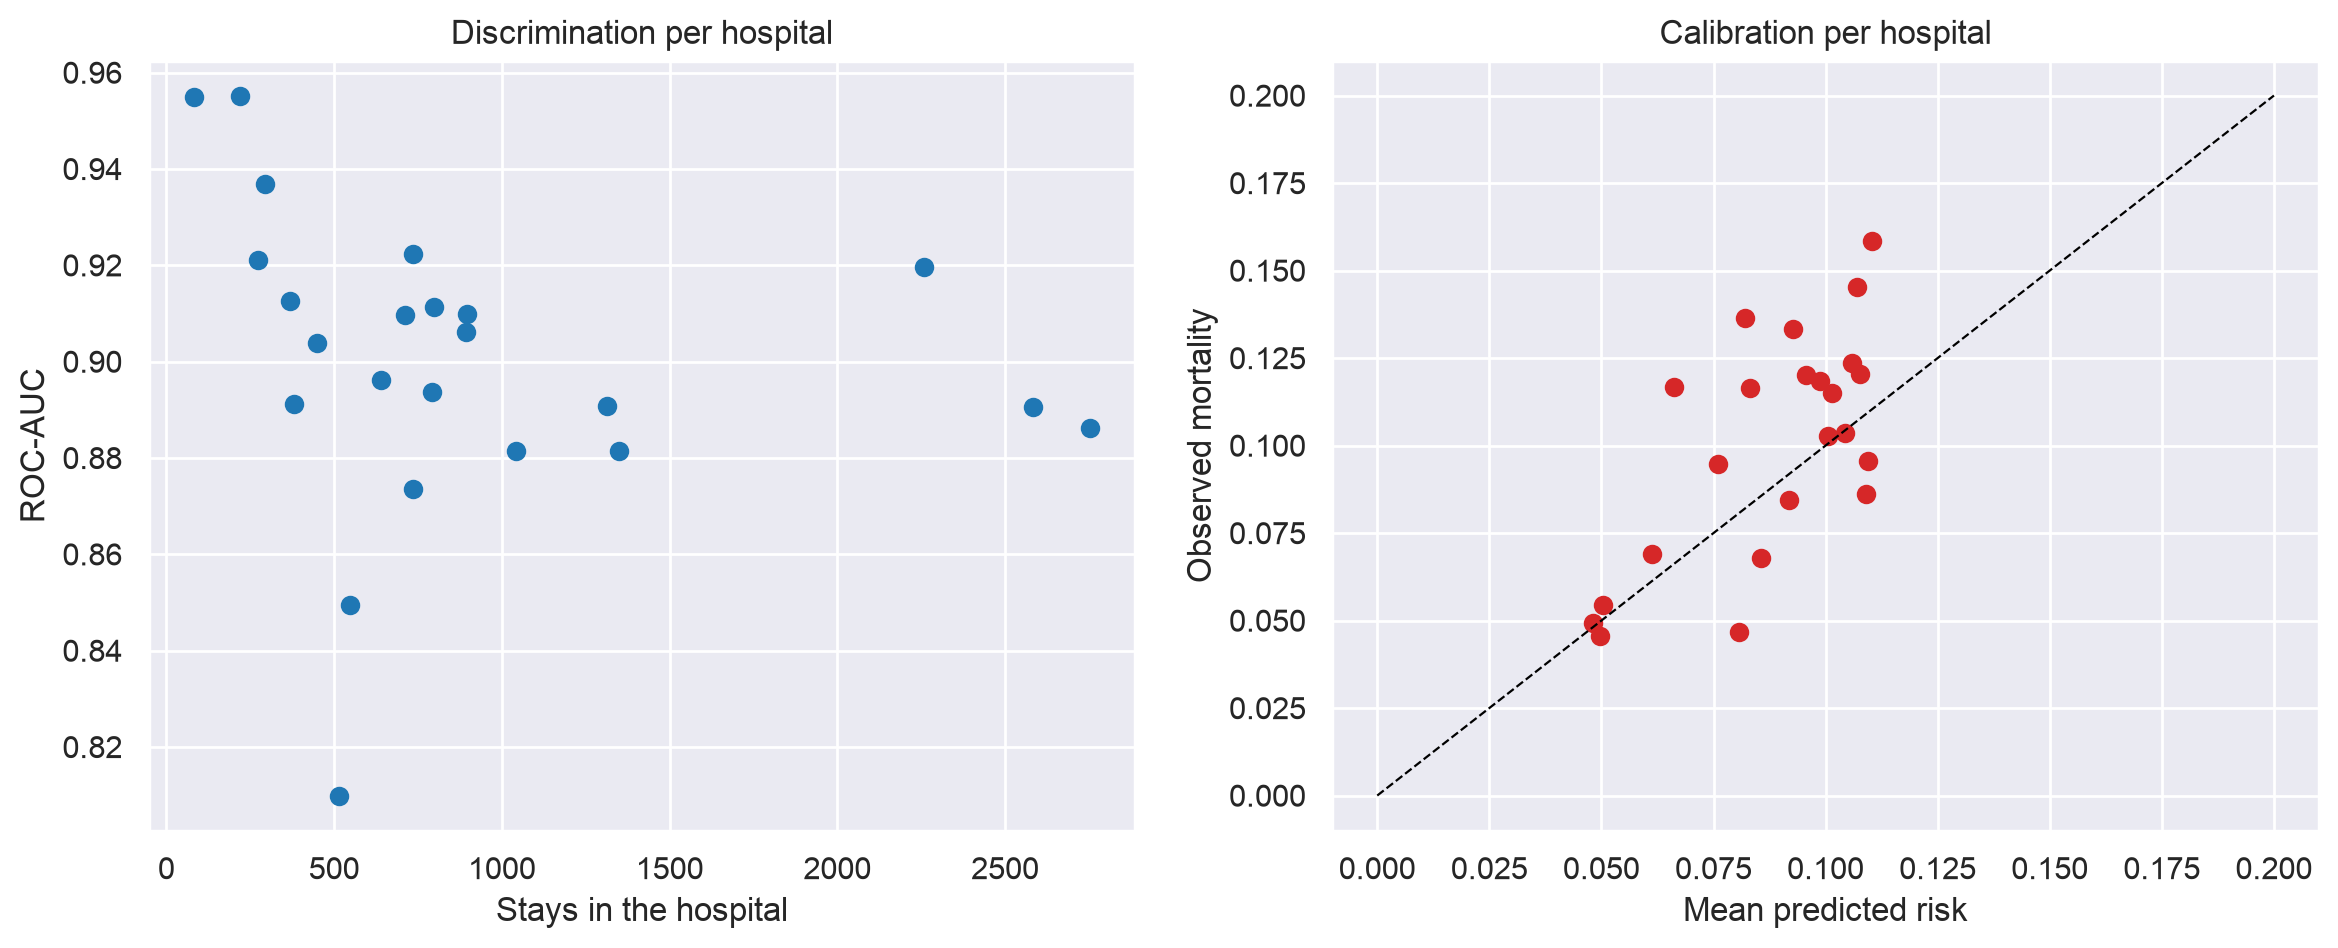

In [47]:
hospital_rows = []
for hospital in set(test_groups):
    mask = test_groups == hospital
    if test_ys[mask].sum() >= 10:  # Enough deaths to compute a ROC-AUC
        hospital_rows.append(
            {
                "stays": mask.sum(),
                "ROC-AUC": metrics.roc_auc_score(
                    test_ys[mask], test_prob_ys["LightGBM"][mask]
                ),
                "observed mortality": test_ys[mask].mean(),
                "mean predicted risk": test_prob_ys["LightGBM"][mask].mean(),
            }
        )
hospital_df = pd.DataFrame(hospital_rows)
display(hospital_df.describe().round(3))

fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(hospital_df["stays"], hospital_df["ROC-AUC"])
ax[0].set(
    xlabel="Stays in the hospital",
    ylabel="ROC-AUC",
    title="Discrimination per hospital",
)
ax[1].scatter(
    hospital_df["mean predicted risk"],
    hospital_df["observed mortality"],
    color="tab:red",
)
ax[1].plot([0, 0.2], [0, 0.2], "k--", lw=0.8)
ax[1].set(
    xlabel="Mean predicted risk",
    ylabel="Observed mortality",
    title="Calibration per hospital",
)
plt.show()

In [48]:
test_info_df = icu_df.iloc[test_idx]
subgroups = {
    "age": pd.cut(
        test_info_df["age"],
        bins=[0, 45, 65, 80, 120],
        right=False,
        labels=["<45", "45-64", "65-79", "80+"],
    ),
    "sex": test_info_df["gender"],
    "ICU type": test_info_df["icu_type"],
    "elective surgery": test_info_df["elective_surgery"].map({0: "no", 1: "yes"}),
}

subgroup_rows = []
for variable, values in subgroups.items():
    for value in sorted(values.dropna().unique()):
        mask = (values == value).to_numpy()
        if test_ys[mask].sum() < 20:  # Too few deaths for a reliable ROC-AUC
            continue
        subgroup_rows.append(
            {
                "variable": variable,
                "group": value,
                "stays": mask.sum(),
                "ROC-AUC": metrics.roc_auc_score(
                    test_ys[mask], test_prob_ys["LightGBM"][mask]
                ),
                "recall": metrics.recall_score(test_ys[mask], pred_ys[mask]),
                "observed mortality": test_ys[mask].mean(),
                "mean predicted risk": test_prob_ys["LightGBM"][mask].mean(),
            }
        )
pd.DataFrame(subgroup_rows).set_index(["variable", "group"]).round(3)

stays  ROC-AUC  recall  observed mortality  \
variable         group                                                      
age              45-64          7318    0.913   0.818               0.073   
                 65-79          6923    0.877   0.816               0.119   
                 80+            3179    0.843   0.848               0.170   
                 <45            3144    0.939   0.763               0.050   
sex              F              9648    0.897   0.861               0.100   
                 M             11795    0.897   0.794               0.104   
ICU type         CCU-CTICU      2655    0.895   0.752               0.081   
                 CTICU          1315    0.909   0.871               0.106   
                 Cardiac ICU    1493    0.923   0.865               0.114   
                 MICU           2882    0.883   0.872               0.130   
                 Med-Surg ICU   8496    0.895   0.825               0.108   
                 Neuro ICU      3308    0.892   0.777               0.088   
                 SICU           1303    0.888   0.780               0.070   
elective surgery no            17644    0.892   0.844               0.116   
                 yes            3808    0.876   0.549               0.040   

                               mean predicted risk  
variable         group                              
age              45-64                       0.070  
                 65-79                       0.103  
                 80+                         0.142  
                 <45                         0.041  
sex              F                           0.095  
                 M                           0.085  
ICU type         CCU-CTICU                   0.066  
                 CTICU                       0.087  
                 Cardiac ICU                 0.103  
                 MICU                        0.133  
                 Med-Surg ICU                0.093  
                 Neuro ICU                   0.070  
                 SICU                        0.058  
elective surgery no                          0.104  
                 yes                         0.026

**Observations**

* The missed deaths look like survivors on day 1: compared with the detected deaths, they were less often ventilated (38% against 76%), had a better motor Glasgow score (5.6 against 4.0), a lower lactate (1.9 against 5.8), more missing values (59 against 51) and more elective surgery (18% against 5%). They were probably stable during the first 24 hours and got worse later, which first-day data can’t see.

* Per hospital (the 23 test hospitals with at least 10 deaths), the ROC-AUC goes from 0.81 to 0.955, and some hospitals are mis-calibrated (right plot). Part of this may come from small hospitals, where there are few deaths, but it shows that a new hospital should check the model, and maybe recalibrate it, before using it.

* By subgroup, the ROC-AUC is the same for women and men (0.897) and similar across ICU types (0.88 to 0.92), but it decreases with age: 0.94 under 45 against 0.84 over 80. With one global threshold, the recall is lowest where deaths are rare: elective surgery (0.55) and patients under 45 (0.76). Their predicted risks are low, so fewer of them reach the threshold.

## 5. Conclusion

### What we did

We predicted in-hospital death from the first 24 hours of 91,713 ICU stays. Following our teacher's feedback, we did not try to beat the leaderboard but asked **where the models overfit** and **how far simple models can go**. All the choices were made with a cross-validation grouped by hospital, and the final evaluation was done once on hospitals never seen in training, with APACHE IVa as a clinical benchmark.

### What worked

*   **LightGBM** is the best model: ROC-AUC **0.906** on new hospitals in cross-validation (**0.897** on the test hospitals), about **0.003** below the best single model reported on Kaggle (0.9097), with one model and no extra feature engineering

*   It **beats APACHE IVa** on the same patients (**0.898** vs **0.856**) and needs fewer alerts to catch 80% of the deaths (**25.1%** of the patients vs **33.6%**)

*   The **logistic regression** with missing indicators is a strong, simple baseline (**0.891** in cross-validation, **0.882** on the test hospitals)

*   Simple clinical features: **they did not help either model** (logistic regression 0.8913 vs 0.8911, LightGBM 0.9063 vs 0.9064): the information was already in the raw features

### Sources of overfitting we identified

| Source | Evidence | What we did |
|:--|:--|:--|
| Training patients | Trees: train **0.999** (LightGBM) and **0.967** (random forest) vs validation **0.906** and **0.887** | Judge models only on new hospitals; tune leaf/tree size |
| Training hospitals | Ranking: random vs grouped split **0.908 vs 0.906** (smaller than the ±); probabilities: test mortality **0.103** vs mean predicted risk **0.099** (logistic regression) | `GroupKFold`, test set of unseen hospitals, no hospital identifiers, recalibration before use |
| Model complexity | More trees: train → 1, validation best at 500 trees (**0.905**) then slowly decreasing | Number of trees close to the best validation point |
| Hospital fingerprints | Hospital recognized **80.6%** of the time from the features (vs 10.7% by chance) | Grouped validation, local check before use |
| Preprocessing on all the data | Naive target encoding: fake **0.946** | Every step that uses the target inside a pipeline |

### What did not work

*   The random forest never beat the logistic regression on ROC-AUC; the APACHE predictions as features, the clinical features and the 30-feature model brought nothing

*   About 20% of the deaths are missed by design (our threshold; 18% on the test hospitals), mostly patients who looked stable on day 1

*   The performance varies between hospitals (ROC-AUC from 0.81 to 0.955), and LightGBM slightly under-estimates the risk

### If we had more time

1.  **Leave-one-hospital-out** evaluation, and a recalibration of the model for each new hospital

2.  **More clinical feature engineering** (first-hour vs first-day changes, organ-failure scores), as in the top Kaggle solutions

3.  **External validation** on another dataset (e.g. MIMIC or eICU on PhysioNet)

### References

*   WiDS Datathon 2020 data: [Kaggle](https://www.kaggle.com/competitions/widsdatathon2020/data); [PhysioNet](https://physionet.org/content/widsdatathon2020/1.0.0/) (Lee, Raffa, Ghassemi et al.)

*   Kaggle leaderboard and write-ups: links in Section 1.3

*   Ren, N., Zhao, X., Zhang, X. (2022). Mortality prediction in ICU using a stacked ensemble model. *Computational and Mathematical Methods in Medicine*

*   Caires Silveira, E., et al. (2022). Prediction of hospital mortality in intensive care unit patients from clinical and laboratory data: a machine learning approach. *World Journal of Critical Care Medicine* 11(5)